# AI624 Assignment 3 — Quantization
## 0. Experimental Setup
GPT-2 small (`openai-community/gpt2`) on WikiText-2 (`wikitext-2-raw-v1`), sequence length 128.
128 training blocks for calibration (fixed seed), validation for tuning, test for final results.

## Imports & settings

In [53]:
%pip install torch transformers datasets psutil pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [54]:
import math, json, random, platform, hashlib
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
import transformers, datasets
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from datasets import load_dataset
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch

# ---------- Fixed settings (same for every experiment) ----------
SEED       = 42
SEQ_LEN    = 128
N_CALIB    = 128
EVAL_BS    = 8      # evaluation + calibration batch size
PROFILE_BS = 1      # profiling batch size
MODEL_ID   = "openai-community/gpt2"

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"      
else:
    DEVICE = "cpu"

## Functions

In [55]:
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if DEVICE == "mps":  torch.mps.manual_seed(s)
    if DEVICE == "cuda": torch.cuda.manual_seed_all(s)


def sync():
    if DEVICE == "mps":    torch.mps.synchronize()
    elif DEVICE == "cuda": torch.cuda.synchronize()


def load_fp32_model():
    model = GPT2LMHeadModel.from_pretrained(MODEL_ID, torch_dtype=torch.float32)
    model = model.to(DEVICE).eval()
    assert all(p.dtype == torch.float32 for p in model.parameters()) and not model.training
    return model


def build_blocks(texts, tok):
    texts = [t for t in texts if t.strip()]
    encoded = tok(texts, add_special_tokens=False)["input_ids"]
    ids = []
    for i, e in enumerate(encoded):
        if i: ids.append(tok.eos_token_id)
        ids.extend(e)
    n = len(ids) // SEQ_LEN
    blocks = torch.tensor(ids[: n * SEQ_LEN], dtype=torch.long).view(n, SEQ_LEN)
    info = {"non_empty_examples": len(texts), "tokens": len(ids), "blocks": n,
            "discarded_tokens": len(ids) - n * SEQ_LEN, "scored_targets": n * (SEQ_LEN - 1)}
    return blocks, info


def fingerprint(blocks):
    return hashlib.sha256(blocks.numpy().tobytes()).hexdigest()[:16]


@torch.no_grad()
def evaluate_lm(model, blocks, bs=EVAL_BS):
    model.eval()
    nll, correct, n = 0.0, 0, 0
    for i in range(0, len(blocks), bs):
        x = blocks[i:i+bs].to(DEVICE)
        logits = model(input_ids=x, use_cache=False).logits[:, :-1].float()  # predict pos 1..127
        y = x[:, 1:]                                                          # true next tokens
        nll += F.cross_entropy(logits.flatten(0, 1), y.flatten(), reduction="sum").item()
        correct += (logits.argmax(-1) == y).sum().item()
        n += y.numel()
    return {"accuracy_%": 100 * correct / n, "nll": nll / n,
            "ppl": math.exp(nll / n), "scored_targets": n}

## main Calling functions

In [56]:
set_seed()

tok = GPT2TokenizerFast.from_pretrained(MODEL_ID)
ds  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

train_blocks, train_info = build_blocks(ds["train"]["text"],      tok)
val_blocks,   val_info   = build_blocks(ds["validation"]["text"], tok)
test_blocks,  test_info  = build_blocks(ds["test"]["text"],       tok)

# Fixed calibration set: 128 train blocks, reused by every PTQ method
g = torch.Generator().manual_seed(SEED)
calib_idx    = torch.randperm(len(train_blocks), generator=g)[:N_CALIB]
calib_blocks = train_blocks[calib_idx]

# Record everything needed to reproduce
setup_record = {
    "model": MODEL_ID, "dataset": "Salesforce/wikitext / wikitext-2-raw-v1",
    "seq_len": SEQ_LEN, "seed": SEED, "n_calib": N_CALIB,
    "calib_indices": calib_idx.tolist(),
    "eval_batch_size": EVAL_BS, "profile_batch_size": PROFILE_BS,
    "precision": "FP32", "use_cache": False, "device": DEVICE,
    "fingerprints": {k: fingerprint(b) for k, b in
                     [("train", train_blocks), ("validation", val_blocks),
                      ("test", test_blocks), ("calibration", calib_blocks)]},
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "transformers": transformers.__version__, "datasets": datasets.__version__,
                 "macOS": platform.mac_ver()[0], "chip": platform.processor()},
}
json.dump(setup_record, open("setup_record.json", "w"), indent=2)

# Check the model loads correctly
_m = load_fp32_model()
n_params = sum(p.numel() for p in _m.parameters())   # tied weights counted once
del _m

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7364.28it/s]


### Results

In [57]:
print("=== Dataset blocks (128 tokens per block, 127 scored targets per block) ===")
display(pd.DataFrame([train_info, val_info, test_info], index=["train", "validation", "test"]))

print("\n=== Settings ===")
print(f"Model                {MODEL_ID}  ({n_params/1e6:.2f} M unique parameters)")
print(f"Calibration          {N_CALIB} train blocks, seed {SEED} (indices in setup_record.json)")
print(f"Batch size           eval/calib = {EVAL_BS}, profiling = {PROFILE_BS}")
print(f"Inference            FP32, eval mode, no gradients, use_cache=False")
print(f"Device               {DEVICE}")

print("\n=== Block fingerprints (must not change between experiments) ===")
for k, v in setup_record["fingerprints"].items():
    print(f"{k:12s} {v}")

print("\n=== Environment ===")
for k, v in setup_record["versions"].items():
    print(f"{k:13s} {v}")

=== Dataset blocks (128 tokens per block, 127 scored targets per block) ===


,non_empty_examples,tokens,blocks,discarded_tokens,scored_targets
train,23767,2415650,18872,34,2396744
validation,2461,249749,1951,21,247777
test,2891,286177,2235,97,283845



=== Settings ===
Model                openai-community/gpt2  (124.44 M unique parameters)
Calibration          128 train blocks, seed 42 (indices in setup_record.json)
Batch size           eval/calib = 8, profiling = 1
Inference            FP32, eval mode, no gradients, use_cache=False
Device               mps

=== Block fingerprints (must not change between experiments) ===
train        c09f281474a95eeb
validation   c033bf55a2004da2
test         cde0f2d28878e25e
calibration  04d77d5854d0d81f

=== Environment ===
python        3.14.2
torch         2.14.1
transformers  5.20.1
datasets      5.1.0
macOS         26.6.2
chip          arm


# 1 Task 1: GPT-2 Baseline and Model Profiling 

##  Task 1.1 — Model Architecture and Quantization Scope

In [58]:
PROJS = ["attn.c_attn", "attn.c_proj", "mlp.c_fc", "mlp.c_proj"]   # quantized in Task 2

def get_proj(model, i, name):
    block = model.transformer.h[i]
    for part in name.split("."):
        block = getattr(block, part)
    return block

@torch.no_grad()
def check_projections(model):
    rows = []
    for name in PROJS:
        layer = get_proj(model, 0, name)
        W, b = layer.weight, layer.bias
        x = torch.randn(1, SEQ_LEN, W.shape[0], device=DEVICE)
        diff = (layer(x) - (x @ W + b)).abs().max().item()
        rows.append({"module": name, "type": type(layer).__name__,
                     "weight (in, out)": tuple(W.shape), "bias": tuple(b.shape),
                     "output channels": W.shape[1], "max diff": diff})
    return pd.DataFrame(rows)




os.makedirs("figures", exist_ok=True)
Q_COLOR, FP_COLOR, RES_COLOR = "#E07B39", "#DDE3EA", "#2B6CB0"   # quantized / FP32 / residual

def _box(ax, x, y, w, h, text, quant=False):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02",
                                fc=Q_COLOR if quant else FP_COLOR, ec="#333333", lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=9,
            color="white" if quant else "#222222", fontweight="bold" if quant else "normal")

def _arrow(ax, x0, y0, x1, y1, color="#333333", style="-|>", **kw):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle=style, color=color, lw=1.2, **kw))

def _legend(ax, q_label="Quantized in Task 2 (weights + input activations)", **kw):
    ax.legend(handles=[Patch(fc=Q_COLOR, ec="#333", label=q_label),
                       Patch(fc=FP_COLOR, ec="#333", label="Kept in FP32")],
              frameon=False, fontsize=9, **kw)

def _save(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def plot_model_overview(save="figures/t11_model_overview.png"):
    """Whole GPT-2: token IDs -> embeddings -> 12 blocks -> ln_f -> tied lm_head -> logits."""
    steps = [("Token IDs\n(B, 128)", False),
             ("wte + wpe\nembeddings\n(B, 128, 768)", False),
             ("Transformer\nblock × 12", True),
             ("ln_f\nfinal LayerNorm", False),
             ("lm_head\n768 → 50257", False),
             ("Logits\n(B, 128, 50257)", False)]
    W, H, gap = 1.9, 1.3, 2.5
    xs = [i * gap for i in range(len(steps))]
    fig, ax = plt.subplots(figsize=(13, 3.8))
    for (text, q), x in zip(steps, xs):
        _box(ax, x, 0, W, H, text, q)
    for x0, x1 in zip(xs[:-1], xs[1:]):
        _arrow(ax, x0 + W/2, 0, x1 - W/2, 0)
    _arrow(ax, xs[4], H/2, xs[1], H/2, color=RES_COLOR, style="<->",
           ls="--", connectionstyle="arc3,rad=0.25")                     # weight tying
    ax.text((xs[1] + xs[4]) / 2, H/2 + 1.15, "tied: lm_head reuses the wte matrix (50257 × 768)",
            ha="center", color=RES_COLOR, fontsize=9)
    ax.set_xlim(xs[0] - W, xs[-1] + W); ax.set_ylim(-1.6, 2.2); ax.axis("off")
    ax.set_title("GPT-2 small — overall structure", fontsize=12)
    _legend(ax, q_label="Contains the 4 quantized projections", loc="lower center", ncol=2)
    _save(fig, save)


def plot_block_diagram(save="figures/t11_block_diagram.png"):
    """One Transformer block in execution order; quantized projections highlighted."""
    steps = [("Input x   (B, 128, 768)", False),
             ("ln_1   (LayerNorm)", False),
             ("attn.c_attn   768 → 2304   (Q, K, V)", True),
             (r"$QK^T/\sqrt{64}$  + causal mask", False),
             ("softmax", False),
             ("× V   (12 heads, concat → 768)", False),
             ("attn.c_proj   768 → 768", True),
             ("+  residual", False),
             ("ln_2   (LayerNorm)", False),
             ("mlp.c_fc   768 → 3072", True),
             ("GELU", False),
             ("mlp.c_proj   3072 → 768", True),
             ("+  residual", False),
             ("Output   (B, 128, 768)", False)]
    W, H = 4.2, 0.55
    ys = [-i for i in range(len(steps))]
    fig, ax = plt.subplots(figsize=(8, 11))

    for a, b, label in [(1, 7, "Attention sub-layer"), (8, 12, "MLP sub-layer")]:
        ax.add_patch(plt.Rectangle((-W/2 - 0.6, ys[b] - 0.45), W + 1.2, ys[a] - ys[b] + 0.9,
                                   fc="#F4F6F9", ec="#C9D1DB", zorder=0))
        ax.text(-W/2 - 0.35, (ys[a] + ys[b]) / 2, label, rotation=90,
                ha="center", va="center", fontsize=10, color="#555555")

    for (text, q), y in zip(steps, ys):
        _box(ax, 0, y, W, H, text, q)
    for y0, y1 in zip(ys[:-1], ys[1:]):
        _arrow(ax, 0, y0 - H/2, 0, y1 + H/2)

    for src, dst, xr in [(0, 7, W/2 + 0.9), (7, 12, W/2 + 1.3)]:     # residual (skip) paths
        ax.plot([W/2, xr, xr], [ys[src], ys[src], ys[dst]], color=RES_COLOR, lw=1.4)
        _arrow(ax, xr, ys[dst], W/2, ys[dst], color=RES_COLOR)
        ax.text(xr + 0.12, (ys[src] + ys[dst]) / 2, "residual", rotation=90,
                va="center", fontsize=9, color=RES_COLOR)

    ax.set_xlim(-W/2 - 0.8, W/2 + 1.8); ax.set_ylim(ys[-1] - 1.3, 0.7); ax.axis("off")
    ax.set_title("One GPT-2 block (repeated 12×) — order of operations", fontsize=12)
    _legend(ax, loc="lower center", ncol=1)
    fig.text(0.5, 0.01, "Dropout layers are identity in eval mode and are omitted.",
             ha="center", fontsize=8, color="#666666")
    _save(fig, save)


def plot_param_breakdown(model, save="figures/t11_param_breakdown.png"):
    """Where the 124.44 M unique parameters are, and how many get quantized."""
    groups = {f"{k} (×12)": 0 for k in PROJS}
    groups.update({"wte (token emb., tied lm_head)": 0, "wpe (positional emb.)": 0,
                   "biases + LayerNorms": 0})
    for name, p in model.named_parameters():                    # tied lm_head counted once
        key = next((k for k in PROJS if name.endswith(f".{k}.weight")), None)
        if key:              groups[f"{key} (×12)"] += p.numel()
        elif "wte" in name:  groups["wte (token emb., tied lm_head)"] += p.numel()
        elif "wpe" in name:  groups["wpe (positional emb.)"] += p.numel()
        else:                groups["biases + LayerNorms"] += p.numel()

    names = list(groups)[::-1]
    vals = [groups[n] / 1e6 for n in names]
    is_q = [n.split()[0] in PROJS for n in names]
    total, q_total = sum(vals), sum(v for v, q in zip(vals, is_q) if q)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.barh(names, vals, color=[Q_COLOR if q else FP_COLOR for q in is_q], edgecolor="#333")
    for b, v in zip(bars, vals):
        ax.text(b.get_width() + 0.4, b.get_y() + b.get_height() / 2, f"{v:.2f} M", va="center", fontsize=9)
    ax.set_xlim(0, max(vals) * 1.2)
    ax.set_xlabel("Parameters (millions)")
    ax.set_title(f"GPT-2 parameters: {q_total:.2f} M of {total:.2f} M "
                 f"({100 * q_total / total:.1f}%) are quantized in Task 2", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    _legend(ax, loc="lower right")
    _save(fig, save)

## run helper functions

In [59]:
model = load_fp32_model()
cfg = model.config

total_params = sum(p.numel() for p in model.parameters())
quant_params = sum(get_proj(model, i, n).weight.numel()
                   for i in range(cfg.n_layer) for n in PROJS)
tied = model.lm_head.weight.data_ptr() == model.transformer.wte.weight.data_ptr()

proj_df = check_projections(model)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 13205.91it/s]


## results

In [60]:
print("=== GPT-2 small ===")
print(f"Blocks: {cfg.n_layer} | Hidden: {cfg.n_embd} | Heads: {cfg.n_head} | "
      f"MLP size: {4 * cfg.n_embd} | Vocab: {cfg.vocab_size}")
print(f"Unique parameters: {total_params/1e6:.2f} M | LM head tied to embedding: {tied}")

print("\n=== One block (order: ln_1 → attn → ln_2 → mlp) ===")
print(model.transformer.h[0])

print("\n=== The 4 projections to quantize (same in all 12 blocks) ===")
display(proj_df)
print("Conv1D stores weight as (in, out) → one output channel = one column → scales over dim 0")

print(f"\nQuantized weights: {quant_params/1e6:.2f} M of {total_params/1e6:.2f} M "
      f"({100*quant_params/total_params:.1f}%)")

=== GPT-2 small ===
Blocks: 12 | Hidden: 768 | Heads: 12 | MLP size: 3072 | Vocab: 50257
Unique parameters: 124.44 M | LM head tied to embedding: True

=== One block (order: ln_1 → attn → ln_2 → mlp) ===
GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c_fc): Conv1D(nf=3072, nx=768)
    (c_proj): Conv1D(nf=768, nx=3072)
    (act): NewGELUActivation()
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

=== The 4 projections to quantize (same in all 12 blocks) ===


,module,type,"weight (in, out)",bias,output channels,max diff
0,attn.c_attn,Conv1D,"(768, 2304)","(2304,)",2304,0.0
1,attn.c_proj,Conv1D,"(768, 768)","(768,)",768,0.0
2,mlp.c_fc,Conv1D,"(768, 3072)","(3072,)",3072,0.0
3,mlp.c_proj,Conv1D,"(3072, 768)","(768,)",768,0.0


Conv1D stores weight as (in, out) → one output channel = one column → scales over dim 0

Quantized weights: 84.93 M of 124.44 M (68.3%)


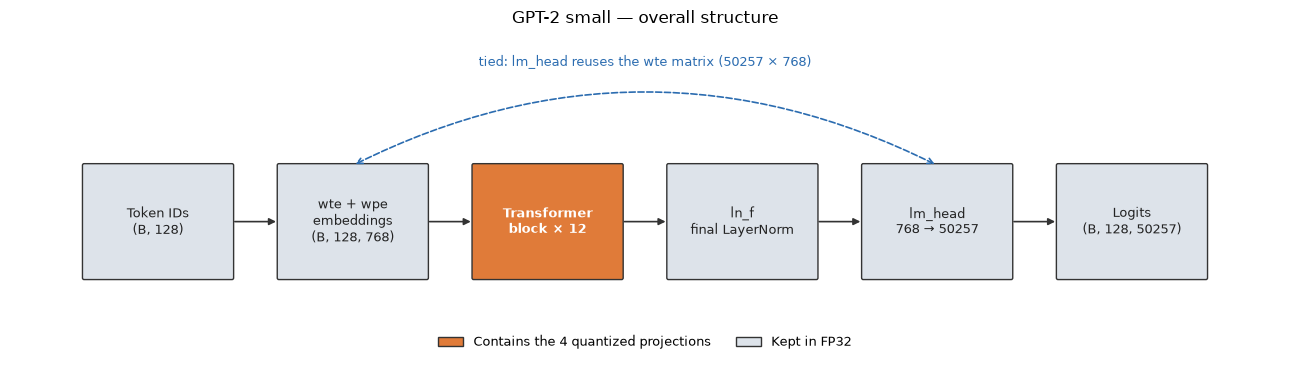

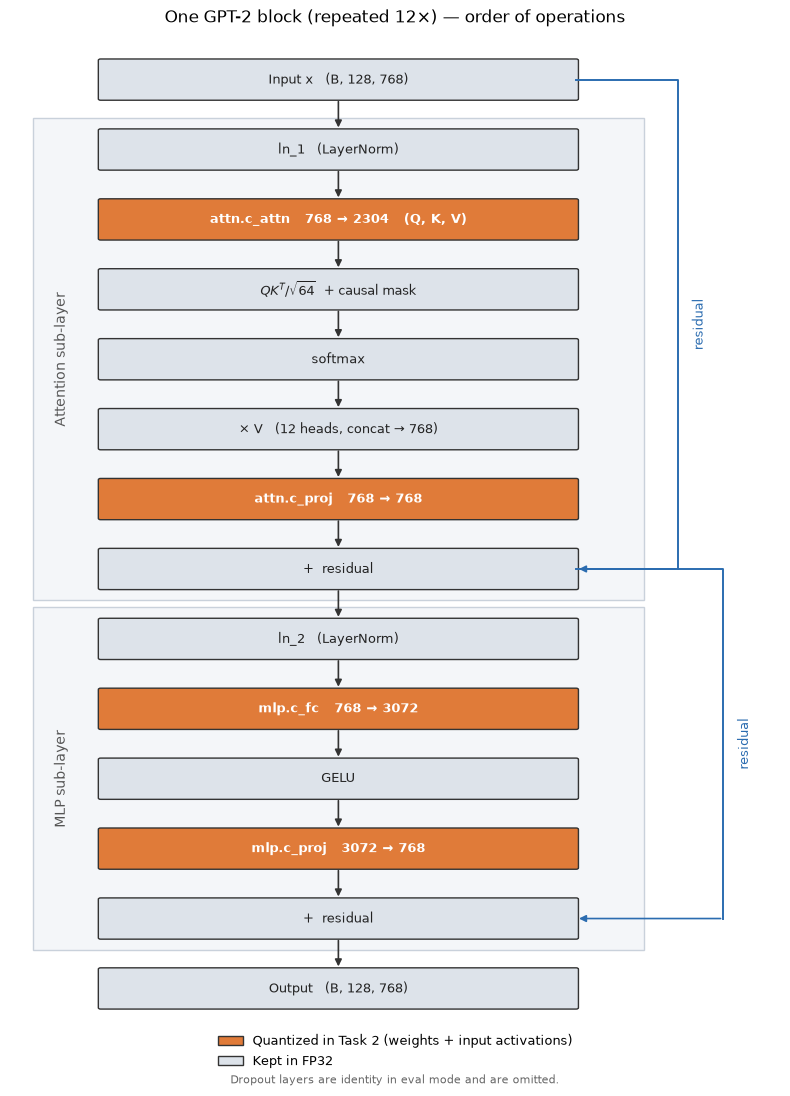

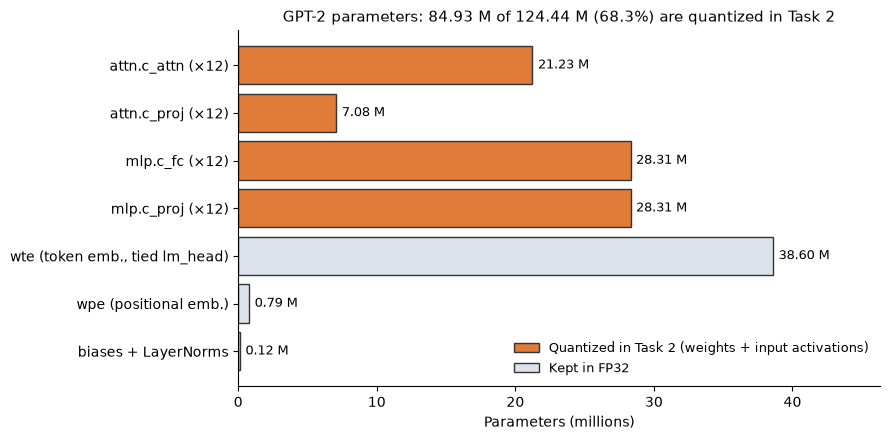

In [61]:
plot_model_overview()
plot_block_diagram()
plot_param_breakdown(model)

##  Task 1.2 — Baseline Language-Model Performance

## helper functions

In [62]:
@torch.no_grad()
def nll_by_position(model, blocks, bs=EVAL_BS):
    total = torch.zeros(SEQ_LEN - 1)
    for i in range(0, len(blocks), bs):
        x = blocks[i:i+bs].to(DEVICE)
        logits = model(input_ids=x, use_cache=False).logits[:, :-1].float()
        loss = F.cross_entropy(logits.transpose(1, 2), x[:, 1:], reduction="none")  # (B, 127)
        total += loss.sum(0).cpu()
    return total / len(blocks)

## calling main function

In [63]:
os.makedirs("results", exist_ok=True)

model = load_fp32_model()                       

base_test = evaluate_lm(model, test_blocks)   
base_val  = evaluate_lm(model, val_blocks)     
pos_nll   = nll_by_position(model, test_blocks)

# Check every test target was scored exactly once
n_scored = base_test.get("scored_targets", base_test.get("targets"))
assert n_scored == test_info["scored_targets"], "Scored target count mismatch"

# Store for the final 13-row table (Task 2.4)
RESULTS = {"FP32 baseline": base_test}
json.dump(base_test, open("results/baseline_fp32.json", "w"), indent=2)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 8742.93it/s]


## results

=== Baseline GPT-2 (FP32) on WikiText-2 ===


,accuracy_%,nll,ppl,scored_targets
test (final),29.2843,4.2734,71.7626,283845
validation (reference),29.0705,4.2759,71.9466,247777


Scored targets: 283,845 = 2235 blocks × 127
Check: exp(NLL) = 71.7626  (= PPL)


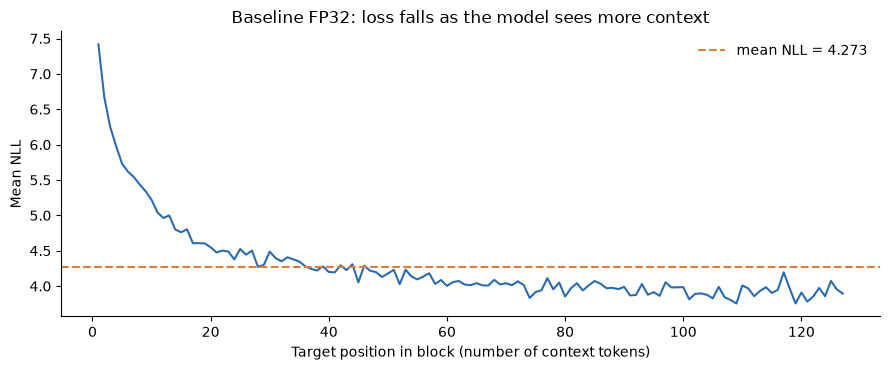

In [64]:
import matplotlib.pyplot as plt

print("=== Baseline GPT-2 (FP32) on WikiText-2 ===")
display(pd.DataFrame([base_test, base_val], index=["test (final)", "validation (reference)"]).round(4))
print(f"Scored targets: {n_scored:,} = {len(test_blocks)} blocks × 127")
print(f"Check: exp(NLL) = {math.exp(base_test['nll']):.4f}  (= PPL)")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(1, SEQ_LEN), pos_nll.numpy(), color="#2B6CB0", lw=1.5)
ax.axhline(base_test["nll"], ls="--", color="#E07B39", label=f"mean NLL = {base_test['nll']:.3f}")
ax.set_xlabel("Target position in block (number of context tokens)")
ax.set_ylabel("Mean NLL")
ax.set_title("Baseline FP32: loss falls as the model sees more context")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/t12_nll_by_position.png", dpi=200); plt.show()

## Task 1.3 — Baseline Profiling

### Functions

In [65]:
import os, time, resource, platform, subprocess, psutil
import matplotlib.pyplot as plt
from torch.profiler import profile, ProfilerActivity

N_WARMUP, N_MEASURE = 10, 30

def analytic_macs(cfg, L=SEQ_LEN, B=PROFILE_BS):
    """MACs per forward pass (dense attention). 1 MAC = 2 FLOPs."""
    d, h, n, V = cfg.n_embd, cfg.n_head, cfg.n_layer, cfg.vocab_size
    macs = {"Attention projections": n * B * L * (d * 3 * d + d * d),
            "Attention matmuls (QKᵀ, A·V)": n * B * 2 * h * L * L * (d // h),
            "MLP projections": n * B * L * (2 * d * 4 * d),
            "Vocabulary head": B * L * d * V}
    macs["Total"] = sum(macs.values())
    df = pd.DataFrame({"GMACs": {k: v / 1e9 for k, v in macs.items()}})
    df["GFLOPs"] = 2 * df["GMACs"]
    df["share_%"] = 100 * df["GMACs"] / df.loc["Total", "GMACs"]
    return df

def gpu_mem():
    return torch.mps.current_allocated_memory() if DEVICE == "mps" else \
           torch.cuda.memory_allocated() if DEVICE == "cuda" else 0

@torch.no_grad()
def profile_model(model, label):
    """Storage, compute, latency, memory for one model (batch 1, 128 tokens)."""
    model.eval()
    x = test_blocks[:PROFILE_BS].to(DEVICE)
    run = lambda: model(input_ids=x, use_cache=False)

    # Storage (tied weights counted once; torch.save stores shared tensors once)
    torch.save(model.state_dict(), "results/_tmp.pt")
    size_mb = os.path.getsize("results/_tmp.pt") / 1e6; os.remove("results/_tmp.pt")

    # Latency: 10 warm-up + 30 timed passes, synced (no profiler attached)
    for _ in range(N_WARMUP): run()
    sync()
    proc = psutil.Process(); proc.cpu_percent(None)
    times = []
    for _ in range(N_MEASURE):
        t0 = time.perf_counter(); run(); sync()
        times.append((time.perf_counter() - t0) * 1000)
    cpu_util = proc.cpu_percent(None)
    t = np.array(times)

    # Peak GPU memory: MPS has no peak counter, so sample after every module
    model_bytes = sum(t.numel() * t.element_size() for t in list(model.parameters()) + list(model.buffers()))
    other = gpu_mem() - model_bytes
    peak = [gpu_mem()]
    hooks = [m.register_forward_hook(lambda *_: peak.append(gpu_mem())) for m in model.modules()]
    run(); sync()
    for h in hooks: h.remove()

    # Profiler pass (separate from timing): FLOPs it can count + top operators
    with profile(activities=[ProfilerActivity.CPU], with_flops=True, record_shapes=True) as prof:
        run(); sync()
    ev = prof.key_averages()
    ops = pd.DataFrame([{"operator": e.key, "calls": e.count, "self CPU ms": e.self_cpu_time_total / 1000,
                         "GFLOPs": (e.flops or 0) / 1e9} for e in ev]) \
            .sort_values("self CPU ms", ascending=False).head(10).reset_index(drop=True)

    macs = analytic_macs(model.config).loc["Total", "GMACs"]
    maxrss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return {
        "config": label,
        "unique_params_M": sum(p.numel() for p in model.parameters()) / 1e6,
        "serialized_MB": size_mb,
        "GMACs": macs, "GFLOPs": 2 * macs,
        "profiler_GFLOPs": sum(e.flops for e in ev if e.flops) / 1e9,
        "latency_mean_ms": t.mean(), "latency_std_ms": t.std(ddof=1),
        "seq_per_s": 1000 * PROFILE_BS / t.mean(), "tokens_per_s": 1000 * x.numel() / t.mean(),
        "peak_gpu_alloc_MB": (max(peak) - other) / 1e6,
        "gpu_driver_MB": torch.mps.driver_allocated_memory() / 1e6 if DEVICE == "mps" else float("nan"),
        "peak_process_rss_MB": maxrss / 1e6 if platform.system() == "Darwin" else maxrss / 1e3,
        "cpu_util_%_one_core": cpu_util,
        "gpu_util_%": "unavailable", "power_W": "unavailable", "energy_mJ": "unavailable",
    }, ops

def environment_info():
    sh = lambda c: subprocess.run(c, shell=True, capture_output=True, text=True).stdout.strip() or "unavailable"
    return pd.Series({
        "CPU / SoC": sh("sysctl -n machdep.cpu.brand_string"),
        "GPU": sh("system_profiler SPDisplaysDataType | grep 'Chipset Model' | cut -d: -f2"),
        "Unified memory (GB)": round(psutil.virtual_memory().total / 1e9, 1),
        "OS": platform.platform(), "PyTorch": torch.__version__,
        "Transformers": transformers.__version__, "Device": DEVICE}, name="value")

### calling main functions

In [66]:
os.makedirs("results", exist_ok=True)
model = load_fp32_model()

base_prof, base_ops = profile_model(model, "FP32 baseline")
mac_df = analytic_macs(model.config)
env = environment_info()

PROFILES = {"FP32 baseline": base_prof}           # reused in Task 2.4
json.dump(base_prof, open("results/baseline_profile.json", "w"), indent=2, default=str)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6386.65it/s]
USDT:2026-10-21 20:55:17 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 20:55:17 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


### results

=== Baseline profile (batch 1, 128 tokens, 10 warm-up + 30 measured) ===


,value
config,FP32 baseline
unique_params_M,124.439808
serialized_MB,497.803017
GMACs,16.11409
GFLOPs,32.22818
profiler_GFLOPs,21.774041
latency_mean_ms,13.538499
latency_std_ms,0.35667
seq_per_s,73.863435
tokens_per_s,9454.519621



=== MACs / FLOPs per forward pass ===


,GMACs,GFLOPs,share_%
Attention projections,3.624,7.248,22.489
"Attention matmuls (QKᵀ, A·V)",0.302,0.604,1.874
MLP projections,7.248,14.496,44.978
Vocabulary head,4.940,9.881,30.659
Total,16.114,32.228,100.000


Profiler counted 21.77 GFLOPs vs analytic 32.23. The gap is the fused attention matmuls, which the profiler does not count; they are added analytically.

=== Top 10 operators (profiler) ===


,operator,calls,self CPU ms,GFLOPs
0,aten::addmm,48,2.107,21.743
1,aten::_local_scalar_dense,1,0.648,0.000
2,aten::diff,1,0.472,0.000
3,aten::scaled_dot_product_attention,12,0.393,0.000
4,aten::arange,2,0.254,0.000
5,aten::add,50,0.247,0.012
6,aten::mul,48,0.196,0.019
7,aten::_to_copy,49,0.181,0.000
8,aten::native_layer_norm,25,0.176,0.000
9,aten::view,228,0.171,0.000



=== Environment ===


,value
CPU / SoC,Apple M2 Pro
GPU,Apple M2 Pro
Unified memory (GB),17.2
OS,macOS-26.6.2-arm64-arm-64bit-Mach-O
PyTorch,2.14.1
Transformers,5.20.1
Device,mps


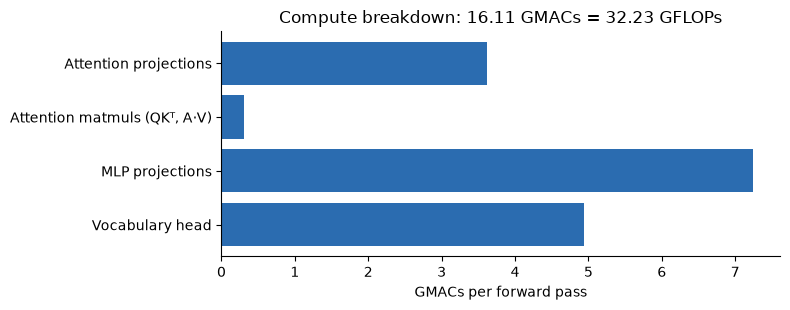

In [67]:
print("=== Baseline profile (batch 1, 128 tokens, 10 warm-up + 30 measured) ===")
display(pd.Series(base_prof).to_frame("value"))

print("\n=== MACs / FLOPs per forward pass ===")
display(mac_df.round(3))
print(f"Profiler counted {base_prof['profiler_GFLOPs']:.2f} GFLOPs vs analytic {base_prof['GFLOPs']:.2f}. "
      "The gap is the fused attention matmuls, which the profiler does not count; they are added analytically.")

print("\n=== Top 10 operators (profiler) ===")
display(base_ops.round(3))

print("\n=== Environment ===")
display(env.to_frame())

parts = mac_df.drop("Total")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(parts.index[::-1], parts["GMACs"][::-1], color="#2B6CB0")
ax.set_xlabel("GMACs per forward pass")
ax.set_title(f"Compute breakdown: {mac_df.loc['Total','GMACs']:.2f} GMACs = {mac_df.loc['Total','GFLOPs']:.2f} GFLOPs")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("figures/t13_mac_breakdown.png", dpi=200); plt.show()

# Task 2 — GPT-2 Post-Training Quantization
## Task 2 — Shared functions

### Task 2 functions (quantizers, quantized layer, evaluation, Linear PTQ, results)

In [68]:
import time
import torch.nn as nn

CONFIGS = [("Static W8A8", 8, "static"), ("Dynamic W8A8", 8, "dynamic"),
           ("Static W4A8", 4, "static"), ("Dynamic W4A8", 4, "dynamic")]
N_ERR_BLOCKS = 32                       # fixed validation blocks for layer-wise error
ERR_BLOCKS = val_blocks[:N_ERR_BLOCKS]
EPS = 1e-12
_CACHE = {}


# ---------- Quantizers (same conventions for every method) ----------
def quantize_weight(W, bits):
    """Symmetric per-output-channel. Conv1D weight is (in, out) -> one scale per column."""
    Qb = 2 ** (bits - 1) - 1
    S = W.abs().amax(dim=0, keepdim=True) / Qb                  # (1, out)
    S = torch.where(S > 0, S, torch.ones_like(S))                # all-zero column -> safe scale
    return torch.clamp(torch.round(W / S), -Qb, Qb), S

def act_qparams(xmin, xmax):
    """Asymmetric unsigned 8-bit. Range always includes 0; zero range handled safely."""
    xmin, xmax = torch.clamp(xmin, max=0.0), torch.clamp(xmax, min=0.0)
    S = (xmax - xmin) / 255
    S = torch.where(S > 0, S, torch.ones_like(S))
    return S, torch.clamp(torch.round(-xmin / S), 0, 255)

def fake_quant_act(x, S, Z):
    """Quantize to uint8, then dequantize (simulated)."""
    return S * (torch.clamp(torch.round(x / S) + Z, 0, 255) - Z)


# ---------- Quantized projection (replaces a GPT-2 Conv1D) ----------
class QuantProj(nn.Module):
    """Integer weights + per-column scales, FP32 bias, A8 input (static or dynamic).
    W: optional precomputed (q, S) for GPTQ.  in_scale: optional SmoothQuant runtime scale."""
    def __init__(self, conv, w_bits, mode, x_range=None, W=None, in_scale=None):
        super().__init__()
        W0 = conv.weight.data
        q, S = (t.to(W0.device) for t in W) if W is not None else quantize_weight(W0, w_bits)
        self.register_buffer("w_int", q.to(torch.int8))                # stored integers
        self.register_buffer("w_scale", S)                             # FP32 scale per column
        self.register_buffer("w_deq", q * S, persistent=False)         # for simulated matmul only
        self.register_buffer("in_scale", in_scale)
        self.bias, self.nf, self.w_bits, self.mode = conv.bias, conv.nf, w_bits, mode
        if mode == "static":
            a_S, a_Z = act_qparams(*[torch.tensor(v, device=W0.device) for v in x_range])
            self.register_buffer("a_scale", a_S)
            self.register_buffer("a_zp", a_Z)
        self.w_err = ((W0 - q * S).pow(2).sum() / (W0.pow(2).sum() + EPS)).item()
        self.track, self.a_num, self.a_den = False, 0.0, 0.0

    def prep(self, x):
        x = x.reshape(-1, x.size(-1))
        return x / self.in_scale if self.in_scale is not None else x

    def act_params(self, x):
        if self.mode == "static":
            return self.a_scale, self.a_zp
        return act_qparams(x.min(), x.max())                   # dynamic: range of current tensor

    def forward(self, x):
        x2 = self.prep(x)
        xq = fake_quant_act(x2, *self.act_params(x2))
        if self.track:                                          # activation reconstruction error
            self.a_num += (x2 - xq).pow(2).sum().item()
            self.a_den += x2.pow(2).sum().item()
        return torch.addmm(self.bias, xq, self.w_deq).view(*x.shape[:-1], self.nf)


# ---------- Model helpers ----------
def proj_names(model):
    """The 48 quantized projections, in execution order."""
    return [f"transformer.h.{i}.{p}" for i in range(model.config.n_layer) for p in PROJS]

def qlayers(model):
    return {n: m for n, m in model.named_modules() if isinstance(m, QuantProj)}

@torch.no_grad()
def run_blocks(model, blocks, bs=EVAL_BS):
    for i in range(0, len(blocks), bs):
        model(input_ids=blocks[i:i+bs].to(DEVICE), use_cache=False)

@torch.no_grad()
def calibrate_ranges(model, blocks):
    """Static calibration: min/max of each projection input over ALL calibration blocks."""
    ranges, hooks = {}, []
    for name in proj_names(model):
        def hook(m, inp, name=name):
            lo, hi = inp[0].min().item(), inp[0].max().item()
            old = ranges.get(name, (float("inf"), float("-inf")))
            ranges[name] = (min(old[0], lo), max(old[1], hi))
        hooks.append(model.get_submodule(name).register_forward_pre_hook(hook))
    run_blocks(model, blocks)
    for h in hooks: h.remove()
    return ranges

def fp32_ranges():
    """Static ranges of the original FP32 model (computed once, reused)."""
    if "ranges" not in _CACHE:
        _CACHE["ranges"] = calibrate_ranges(load_fp32_model(), calib_blocks)
    return _CACHE["ranges"]

def quantize_model(model, w_bits, mode, ranges=None, new_weights=None, in_scales=None):
    """Swap the 48 projections for QuantProj."""
    for name in proj_names(model):
        parent_name, child = name.rsplit(".", 1)
        parent = model.get_submodule(parent_name)
        setattr(parent, child, QuantProj(
            getattr(parent, child), w_bits, mode,
            x_range=ranges[name] if mode == "static" else None,
            W=(new_weights or {}).get(name), in_scale=(in_scales or {}).get(name)))
    return model


# ---------- Errors, integer check, sizes ----------
@torch.no_grad()
def layer_errors(model, blocks=None):
    """E_W and E_X per layer on fixed validation blocks."""
    layers = qlayers(model)
    for m in layers.values(): m.track, m.a_num, m.a_den = True, 0.0, 0.0
    run_blocks(model, ERR_BLOCKS if blocks is None else blocks)
    rows = []
    for n, m in layers.items():
        m.track = False
        rows.append({"block": int(n.split(".")[2]), "proj": n.split(".", 3)[3],
                     "E_W": m.w_err, "E_X": m.a_num / (m.a_den + EPS)})
    return pd.DataFrame(rows)

@torch.no_grad()
def check_integer_path(model, name="transformer.h.0.attn.c_attn"):
    """Y = S_X·S_W ⊙ (Xq·Wq − Z_X·colsum(Wq)) + b, compared with the simulated output."""
    layer, store = model.get_submodule(name), {}
    h = layer.register_forward_pre_hook(lambda m, inp: store.update(x=inp[0]))
    model(input_ids=val_blocks[:1].to(DEVICE), use_cache=False); h.remove()
    x = layer.prep(store["x"])
    S_X, Z_X = layer.act_params(x)
    cpu64 = lambda t: t.cpu().double()                    # move to CPU first (MPS has no float64)
    Xq = cpu64(torch.clamp(torch.round(x / S_X) + Z_X, 0, 255))          # uint8 values
    Wq = cpu64(layer.w_int)                                              # int8 / int4 values
    acc = Xq @ Wq                                     # INT32 accumulation (exact in float64 here)
    acc = acc - cpu64(Z_X) * Wq.sum(0)                # activation zero-point correction
    y_int = acc * (cpu64(S_X) * cpu64(layer.w_scale)) + cpu64(layer.bias)
    y_sim = cpu64(layer(store["x"]).reshape(-1, layer.nf))
    return {"max |acc| (< 2^31)": acc.abs().max().item(),
            "max |Y_int − Y_sim|": (y_int - y_sim).abs().max().item()}

def count_params(model):
    """FP32 parameters + integer weights (stored as buffers)."""
    return sum(p.numel() for p in model.parameters()) + sum(m.w_int.numel() for m in qlayers(model).values())

def packed_size_MB(model, w_bits):
    """Theoretical size with weights packed at w_bits (incl. all scales / zero-points)."""
    q = qlayers(model).values()
    fp = sum(p.numel() for p in model.parameters()) * 4
    qw = sum(m.w_int.numel() for m in q) * w_bits / 8
    meta = sum(m.w_scale.numel() * 4 + (m.in_scale.numel() * 4 if m.in_scale is not None else 0)
               + (8 if m.mode == "static" else 0) for m in q)
    return (fp + qw + meta) / 1e6


# ---------- Shared evaluation (used by all three methods) ----------
def evaluate_config(model, label, bits):
    """Test metrics + full profile + layer errors + integer check for one quantized model."""
    import gc
    gc.collect()
    if DEVICE == "mps": torch.mps.empty_cache()
    res = evaluate_lm(model, test_blocks)
    prof, _ = profile_model(model, label)
    prof["unique_params_M"] = count_params(model) / 1e6
    prof["packed_size_MB (theory)"] = packed_size_MB(model, bits)
    RESULTS[label], PROFILES[label] = res, prof
    return {"eval": res, "prof": prof, "errs": layer_errors(model), "int_check": check_integer_path(model)}

def run_all(method_fn):
    """Run one method on all 4 configurations."""
    out = {}
    for name, bits, mode in CONFIGS:
        t0 = time.perf_counter()
        out[name] = method_fn(name, bits, mode)
        e = out[name]["eval"]
        print(f"{method_fn.__name__:16s} {name:13s} PPL {e['ppl']:8.2f} | Acc {e['accuracy_%']:.2f}% "
              f"| {time.perf_counter() - t0:.0f}s")
    return out


# ---------- Method 1: Linear PTQ ----------
def run_ptq(name, bits, mode):
    """Round-to-nearest PTQ from the original checkpoint; static ranges from FP32 calibration."""
    model = quantize_model(load_fp32_model(), bits, mode, fp32_ranges())
    out = evaluate_config(model, f"Linear {name}", bits)
    del model
    return out


# ---------- Theoretical analysis (no INT8/INT4 kernels on MPS) ----------
E_FP32_MAC, E_INT8_MAC, E_DRAM_BYTE = 4.6, 0.3, 160.0    # pJ, Horowitz ISSCC 2014 (45 nm)

def theoretical_table():
    """Integer vs FP32 MACs, extra quantization ops, weight bytes, arithmetic + DRAM energy."""
    model = load_fp32_model(); cfg = model.config
    d, n, L = cfg.n_embd, cfg.n_layer, SEQ_LEN * PROFILE_BS
    mac = analytic_macs(cfg)
    q_mac = (mac.loc["Attention projections", "GMACs"] + mac.loc["MLP projections", "GMACs"]) * 1e9
    all_mac = mac.loc["Total", "GMACs"] * 1e9
    in_el, out_el = n * L * 7 * d, n * L * 9 * d                  # projection input / output elements
    n_q = sum(model.get_submodule(p).weight.numel() for p in proj_names(model))
    n_fp = sum(p.numel() for p in model.parameters()) - n_q
    rows = []
    for name, bits, mode in [("FP32 baseline", 32, None)] + CONFIGS:
        int_mac = 0 if bits == 32 else q_mac
        extra = 0 if bits == 32 else in_el * (4 + (2 if mode == "dynamic" else 0)) + out_el * 2
        w_bytes = n_fp * 4 + n_q * bits / 8
        e_arith = ((all_mac - int_mac) * E_FP32_MAC + int_mac * E_INT8_MAC) * 1e-9        # mJ
        rows.append({"config": name, "GMACs total": all_mac / 1e9, "INT GMACs": int_mac / 1e9,
                     "FP32 GMACs": (all_mac - int_mac) / 1e9, "extra quant ops (M)": extra / 1e6,
                     "weight bytes / pass (MB)": w_bytes / 1e6, "arith energy (mJ)": e_arith,
                     "pJ / MAC": e_arith * 1e9 / all_mac, "pJ / FLOP": e_arith * 1e9 / (2 * all_mac),
                     "weight DRAM energy (mJ)": w_bytes * E_DRAM_BYTE * 1e-9})
    return pd.DataFrame(rows).set_index("config")


# ---------- Results helpers (reused by 2.1, 2.2, 2.3) ----------
SUMMARY_COLS = ["accuracy_%", "nll", "ppl", "ΔPPL", "unique_params_M", "serialized_MB",
                "packed_size_MB (theory)", "GMACs", "GFLOPs", "latency_mean_ms", "latency_std_ms",
                "seq_per_s", "tokens_per_s", "peak_gpu_alloc_MB", "peak_process_rss_MB",
                "cpu_util_%_one_core", "energy_mJ"]

def summary_table(labels):
    """Accuracy + profiling rows for the given labels (FP32 baseline first)."""
    labels = ["FP32 baseline"] + labels
    df = pd.DataFrame([{**RESULTS[l], **PROFILES[l]} for l in labels], index=labels)
    for c in df.columns:
        try: df[c] = pd.to_numeric(df[c])
        except (ValueError, TypeError): pass
    df["ΔPPL"] = df["ppl"] - df.loc["FP32 baseline", "ppl"]
    return df.reindex(columns=SUMMARY_COLS)

def error_table(R):
    """Mean E_W and E_X per projection type for each configuration."""
    err = pd.concat([v["errs"].assign(config=k) for k, v in R.items()])
    return err.pivot_table(index="config", columns="proj", values=["E_W", "E_X"], aggfunc="mean") \
              .reindex([c[0] for c in CONFIGS])

def plot_layer_errors(R, title, path):
    """Row 1: weight error per block (W8 vs W4). Row 2: activation error per block (4 configs)."""
    err = pd.concat([v["errs"].assign(config=k) for k, v in R.items()])
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
    for j, proj in enumerate(PROJS):
        for k in R:
            d = err[(err.config == k) & (err.proj == proj)]
            if "Static" in k:                                  # E_W is identical for static/dynamic
                axes[0, j].plot(d.block, d.E_W, marker="o", ms=3, label=k.split()[1])
            axes[1, j].plot(d.block, d.E_X, marker="o", ms=3, label=k)
        axes[0, j].set_title(proj); axes[1, j].set_xlabel("block")
        for ax in axes[:, j]:
            ax.set_yscale("log"); ax.spines[["top", "right"]].set_visible(False)
    axes[0, 0].set_ylabel("weight error $E_W$"); axes[1, 0].set_ylabel("activation error $E_X$")
    axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()

def show_method(R, method, fig_path):
    """Summary table, integer check, error table and error plot for one method."""
    print(f"=== {method} vs FP32 (test split; quantization SIMULATED on {DEVICE}) ===")
    display(summary_table([f"{method} {k}" for k in R]).round(3))
    print("\n=== Integer-path check (block 0 attn.c_attn) ===")
    display(pd.DataFrame({k: v["int_check"] for k, v in R.items()}).T)
    print(f"\n=== Mean layer-wise normalized error ({N_ERR_BLOCKS} fixed validation blocks) ===")
    display(error_table(R).map(lambda v: f"{v:.2e}"))
    plot_layer_errors(R, f"{method}: layer-wise normalized reconstruction error", fig_path)

## Task 2.1 — Static and Dynamic Linear PTQ

In [69]:
set_seed()
PTQ = run_all(run_ptq)
theory_df = theoretical_table()

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 11818.09it/s]
USDT:2026-10-21 20:55:49 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 20:55:49 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_ptq          Static W8A8   PPL    76.35 | Acc 28.49% | 32s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 8318.02it/s]
USDT:2026-10-21 20:56:20 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 20:56:20 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_ptq          Dynamic W8A8  PPL    75.47 | Acc 28.75% | 32s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6775.64it/s]
USDT:2026-10-21 20:56:52 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 20:56:52 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_ptq          Static W4A8   PPL   125.13 | Acc 23.94% | 31s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6995.00it/s]
USDT:2026-10-21 20:57:23 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 20:57:23 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_ptq          Dynamic W4A8  PPL   121.50 | Acc 24.18% | 31s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7521.96it/s]


## Results

=== Linear vs FP32 (test split; quantization SIMULATED on mps) ===


,accuracy_%,nll,ppl,ΔPPL,unique_params_M,serialized_MB,packed_size_MB (theory),GMACs,GFLOPs,latency_mean_ms,latency_std_ms,seq_per_s,tokens_per_s,peak_gpu_alloc_MB,peak_process_rss_MB,cpu_util_%_one_core,energy_mJ
FP32 baseline,29.284,4.273,71.763,0.000,124.44,497.803,NaN,16.114,32.228,13.538,0.357,73.863,9454.520,524.367,1394.901,41.2,unavailable
Linear Static W8A8,28.495,4.335,76.346,4.583,124.44,243.370,243.287,16.114,32.228,14.815,2.048,67.497,8639.634,609.634,1394.901,42.6,unavailable
Linear Dynamic W8A8,28.747,4.324,75.467,3.705,124.44,243.343,243.287,16.114,32.228,19.603,1.420,51.011,6529.449,609.633,1394.901,53.0,unavailable
Linear Static W4A8,23.935,4.829,125.135,53.372,124.44,243.370,200.820,16.114,32.228,15.199,3.092,65.794,8421.608,609.634,1394.901,42.5,unavailable
Linear Dynamic W4A8,24.180,4.800,121.498,49.735,124.44,243.343,200.820,16.114,32.228,16.860,2.606,59.310,7591.735,609.633,1394.901,56.1,unavailable



=== Integer-path check (block 0 attn.c_attn) ===


,max |acc| (< 2^31),max |Y_int − Y_sim|
Static W8A8,181701.0,0.000009
Dynamic W8A8,193647.0,0.000008
Static W4A8,9900.0,0.000008
Dynamic W4A8,10552.0,0.000007



=== Mean layer-wise normalized error (32 fixed validation blocks) ===


E_W                                          E_X  \
proj         attn.c_attn attn.c_proj  mlp.c_fc mlp.c_proj attn.c_attn   
config                                                                  
Static W8A8     7.81e-05    8.31e-05  6.72e-05   2.50e-04    1.42e-03   
Dynamic W8A8    7.81e-05    8.31e-05  6.72e-05   2.50e-04    1.30e-03   
Static W4A8     2.56e-02    2.65e-02  2.17e-02   5.49e-02    1.44e-03   
Dynamic W4A8    2.56e-02    2.65e-02  2.17e-02   5.49e-02    1.34e-03   

                                               
proj         attn.c_proj  mlp.c_fc mlp.c_proj  
config                                         
Static W8A8     1.46e-03  3.90e-03   1.56e-02  
Dynamic W8A8    1.10e-03  3.73e-03   1.42e-02  
Static W4A8     1.47e-03  4.04e-03   1.64e-02  
Dynamic W4A8    1.10e-03  3.86e-03   1.53e-02

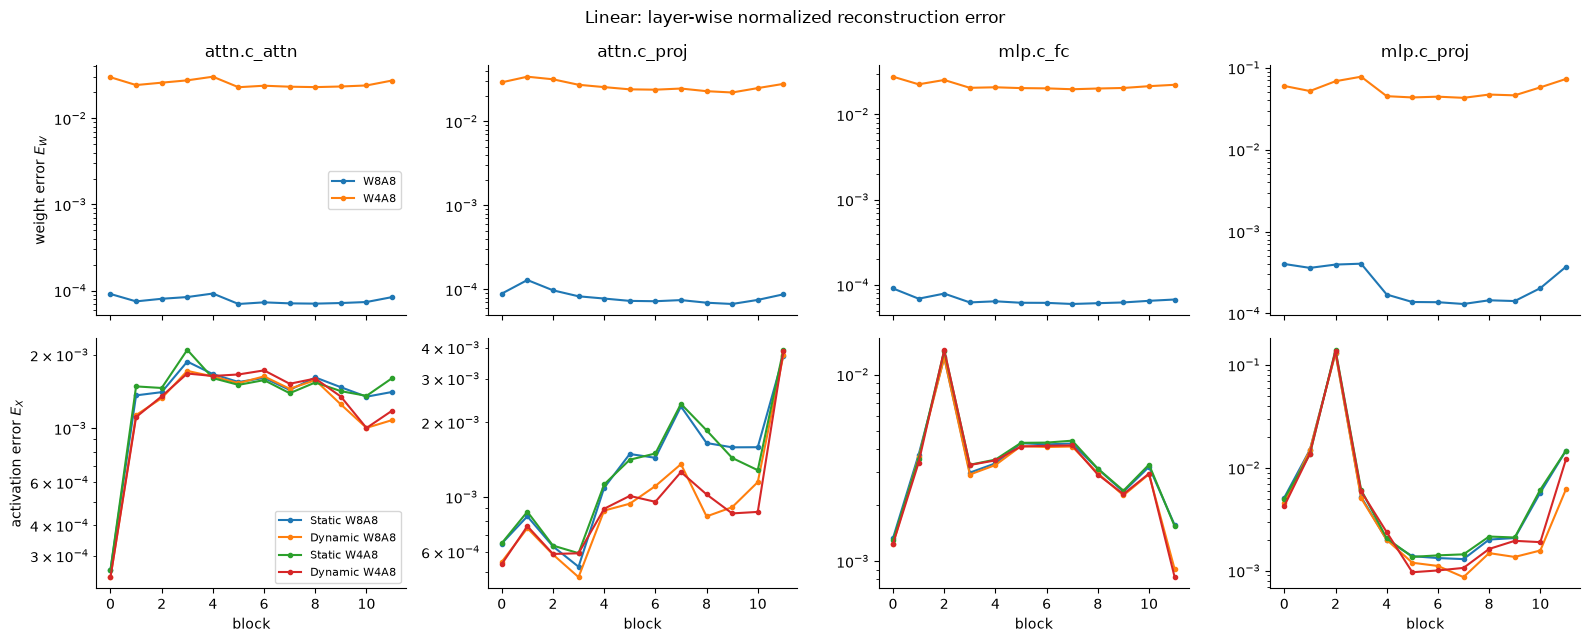


=== Theoretical analysis (no INT8/INT4 kernels on MPS) ===


,GMACs total,INT GMACs,FP32 GMACs,extra quant ops (M),weight bytes / pass (MB),arith energy (mJ),pJ / MAC,pJ / FLOP,weight DRAM energy (mJ)
config,,,,,,,,,
FP32 baseline,16.114,0.000,16.114,0.000,497.759,74.125,4.600,2.300,79.641
Static W8A8,16.114,10.872,5.242,54.264,242.955,27.377,1.699,0.849,38.873
Dynamic W8A8,16.114,10.872,5.242,70.779,242.955,27.377,1.699,0.849,38.873
Static W4A8,16.114,10.872,5.242,54.264,200.488,27.377,1.699,0.849,32.078
Dynamic W4A8,16.114,10.872,5.242,70.779,200.488,27.377,1.699,0.849,32.078


In [70]:
show_method(PTQ, "Linear", "figures/t21_layer_errors.png")

print("\n=== Theoretical analysis (no INT8/INT4 kernels on MPS) ===")
display(theory_df.round(3))

## Task 2.2 — SmoothQuant and Outlier Analysis

In [71]:
# ---------- Method 2: SmoothQuant ----------
ALPHAS = [0.25, 0.5, 0.75]

@torch.no_grad()
def act_absmax():
    """max|X| per input channel of every projection (FP32 model, calibration data)."""
    if "absmax" not in _CACHE:
        model, amax = load_fp32_model(), {}
        def hook(m, inp, n):
            a = inp[0].reshape(-1, inp[0].size(-1)).abs().amax(0)
            amax[n] = torch.maximum(amax[n], a) if n in amax else a
        hs = [model.get_submodule(n).register_forward_pre_hook(lambda m, i, n=n: hook(m, i, n))
              for n in proj_names(model)]
        run_blocks(model, calib_blocks)
        for h in hs: h.remove()
        _CACHE["absmax"] = amax
    return _CACHE["absmax"]

@torch.no_grad()
def apply_smoothing(model, alpha):
    """X' = X/s, W' = s·W.  c_attn, c_fc: 1/s folded into ln_1, ln_2.  Both c_proj: divide at runtime."""
    in_scales = {}
    for i, blk in enumerate(model.transformer.h):
        for proj, ln in [("attn.c_attn", blk.ln_1), ("attn.c_proj", None),
                         ("mlp.c_fc", blk.ln_2), ("mlp.c_proj", None)]:
            name = f"transformer.h.{i}.{proj}"
            conv = model.get_submodule(name)
            s = (act_absmax()[name] + 1e-5) ** alpha / (conv.weight.abs().amax(1) + 1e-5) ** (1 - alpha)
            conv.weight.mul_(s[:, None])                      # scale weight rows (input channels)
            if ln is not None:
                ln.weight.div_(s); ln.bias.div_(s)            # LayerNorm now outputs X / s
            else:
                in_scales[name] = s                           # runtime division (included in profiling)
                conv.register_forward_pre_hook(lambda m, inp, s=s: (inp[0] / s,))
    return in_scales

@torch.no_grad()
def check_equivalence(alpha):
    """Smoothed vs original FP32 logits on 4 fixed validation blocks."""
    x = val_blocks[:4].to(DEVICE)
    ref = load_fp32_model()(input_ids=x, use_cache=False).logits
    sm = load_fp32_model(); apply_smoothing(sm, alpha)
    d = sm(input_ids=x, use_cache=False).logits - ref
    return {"alpha": alpha, "max |Δ logits|": d.abs().max().item(),
            "relative error": (d.norm() / ref.norm()).item()}

def build_smoothquant(bits, mode, alpha):
    """Fresh model -> smooth -> recalibrate static ranges -> quantize (2.1 quantizer)."""
    model = load_fp32_model()
    in_scales = apply_smoothing(model, alpha)
    ranges = calibrate_ranges(model, calib_blocks) if mode == "static" else None
    return quantize_model(model, bits, mode, ranges, in_scales=in_scales)

def run_smoothquant(name, bits, mode):
    """Choose α by validation PPL, then evaluate on test (same evaluation as 2.1)."""
    val_ppl = {a: evaluate_lm(build_smoothquant(bits, mode, a), val_blocks)["ppl"] for a in ALPHAS}
    best = min(val_ppl, key=val_ppl.get)
    out = evaluate_config(build_smoothquant(bits, mode, best), f"SmoothQuant {name}", bits)
    return {**out, "alpha": best, "val_ppl": val_ppl}


# ---------- Outlier analysis (blocks 0, 5, 11; same validation sequences) ----------
DIST_NAMES = [f"transformer.h.{i}.{p}" for i in (0, 5, 11) for p in PROJS]

@torch.no_grad()
def distribution_analysis(model, ranges):
    """Max, p99, top/median channel ratio, static clipping %, and errors for X and W."""
    xs = {n: [] for n in DIST_NAMES}
    hs = [model.get_submodule(n).register_forward_pre_hook(
          lambda m, inp, n=n: xs[n].append(inp[0].reshape(-1, inp[0].size(-1)).float().cpu()))
          for n in DIST_NAMES]
    run_blocks(model, val_blocks[:EVAL_BS])
    for h in hs: h.remove()
    err = lambda a, b: ((a - b).pow(2).sum() / (a.pow(2).sum() + EPS)).item()
    p99 = lambda t: torch.quantile(t.flatten()[torch.randperm(t.numel())[:500_000]].abs(), 0.99).item()
    rows, data = [], {}
    for n in DIST_NAMES:
        x, W = torch.cat(xs[n]), model.get_submodule(n).weight.detach().float().cpu()
        S, Z = act_qparams(torch.tensor(ranges[n][0]), torch.tensor(ranges[n][1]))
        x_st = fake_quant_act(x, S, Z)                              # static A8 approximation
        x_dy = fake_quant_act(x, *act_qparams(x.min(), x.max()))    # dynamic A8 approximation
        w8 = torch.mul(*quantize_weight(W, 8))
        x_ch, w_ch = x.abs().amax(0), W.abs().amax(1)               # per input channel
        rows.append({"layer": n[12:], "X max": x.abs().max().item(), "X p99": p99(x),
                     "X top/median ch": (x_ch.max() / x_ch.median()).item(),
                     "W max": W.abs().max().item(), "W p99": p99(W),
                     "W top/median ch": (w_ch.max() / w_ch.median()).item(),
                     "static clip %": 100 * ((x < -Z * S) | (x > (255 - Z) * S)).float().mean().item(),
                     "E_X static": err(x, x_st), "E_X dynamic": err(x, x_dy),
                     "E_W W8": err(W, w8), "E_W W4": err(W, torch.mul(*quantize_weight(W, 4)))})
        data[n] = {"x_ch": x_ch, "w_ch": w_ch, "x": x.flatten()[::10], "x_st": x_st.flatten()[::10],
                   "w": W.flatten(), "w8": w8.flatten()}
    return pd.DataFrame(rows).set_index("layer"), data

def plot_grid(datasets, kind, title, path):
    """kind 'x_ch'/'w_ch': per-channel max |·|.  kind 'x'/'w': histogram of tensor vs its quantized version."""
    fig, axes = plt.subplots(3, 4, figsize=(16, 8))
    for ax, n in zip(axes.flat, DIST_NAMES):
        for label, d in datasets:
            if kind.endswith("_ch"):
                ax.plot(d[n][kind].numpy(), lw=0.7, label=label); ax.set_yscale("log")
            else:
                v, vq = d[n][kind].numpy(), d[n]["x_st" if kind == "x" else "w8"].numpy()
                bins = np.linspace(v.min(), v.max(), 100)
                ax.hist(v, bins=bins, log=True, alpha=0.5, label=f"{label} original")
                ax.hist(vq, bins=bins, log=True, histtype="step", label=f"{label} quantized")
        ax.set_title(n[12:], fontsize=9); ax.spines[["top", "right"]].set_visible(False)
    axes[0, 0].legend(fontsize=7); fig.suptitle(title)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

def compare_methods(*named):
    """Test PPL, mean E_W, mean E_X per config for each method side by side."""
    rows = [{"config": k, "method": m, "test PPL": v["eval"]["ppl"], "mean E_W": v["errs"].E_W.mean(),
             "mean E_X": v["errs"].E_X.mean()} for m, R in named for k, v in R.items()]
    return pd.DataFrame(rows).pivot(index="config", columns="method").reindex([c[0] for c in CONFIGS])

### run functions

In [72]:
set_seed()

# Before smoothing
before_df, before = distribution_analysis(load_fp32_model(), fp32_ranges())

# Equivalence check (no quantization)
equiv_df = pd.DataFrame([check_equivalence(a) for a in ALPHAS]).set_index("alpha")

# α selection + 4 configs
SQ = run_all(run_smoothquant)
alpha_df = pd.DataFrame({k: {**{f"val PPL α={a}": p for a, p in v["val_ppl"].items()},
                             "chosen α": v["alpha"]} for k, v in SQ.items()}).T

# After smoothing (α of Static W8A8), recalibrated ranges, same validation sequences
A = SQ["Static W8A8"]["alpha"]
sm = load_fp32_model(); apply_smoothing(sm, A)
after_df, after = distribution_analysis(sm, calibrate_ranges(sm, calib_blocks)); del sm

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7146.97it/s]
USDT:2026-10-21 20:59:34 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 20:59:34 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_smoothquant  Static W8A8   PPL    72.66 | Acc 29.17% | 122s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6137.24it/s]
USDT:2026-10-21 21:01:34 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 21:01:34 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_smoothquant  Dynamic W8A8  PPL    72.58 | Acc 29.15% | 120s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7500.87it/s]
USDT:2026-10-21 21:03:34 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 21:03:34 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_smoothquant  Static W4A8   PPL   151.79 | Acc 21.90% | 120s


Could not reach the Hub ([SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1081)). Using cached commit hash for 'openai-community/gpt2'.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7454.75it/s]
USDT:2026-10-21 21:06:04 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 21:06:04 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_smoothquant  Dynamic W4A8  PPL   148.26 | Acc 22.14% | 149s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7851.02it/s]


## Results

=== BEFORE smoothing (blocks 0, 5, 11) ===


,X max,X p99,X top/median ch,W max,W p99,W top/median ch,static clip %,E_X static,E_X dynamic,E_W W8,E_W W4
layer,,,,,,,,,,,
h.0.attn.c_attn,0.8031,0.3182,2.1747,2.8436,0.6634,2.7545,0.0000,0.0003,0.0002,0.0001,0.0300
h.0.attn.c_proj,2.0790,0.7056,5.2515,3.3171,0.5910,3.1059,0.0001,0.0006,0.0006,0.0001,0.0292
h.0.mlp.c_fc,2.8819,0.4502,6.8148,4.5877,0.4162,6.7936,0.0000,0.0013,0.0013,0.0001,0.0276
h.0.mlp.c_proj,11.0651,0.7078,8.1929,6.1433,0.2337,21.4955,0.0000,0.0051,0.0037,0.0004,0.0600
h.5.attn.c_attn,8.2153,0.9561,9.8571,1.3924,0.3551,2.5477,0.0000,0.0016,0.0015,0.0001,0.0230
h.5.attn.c_proj,3.9123,1.2341,3.4236,1.9833,0.2544,5.0760,0.0000,0.0012,0.0007,0.0001,0.0241
h.5.mlp.c_fc,11.2273,0.6568,17.5751,1.9646,0.3412,3.7638,0.0000,0.0043,0.0041,0.0001,0.0203
h.5.mlp.c_proj,5.4699,0.6728,4.6233,2.8407,0.2648,7.5543,11.0793,0.0013,0.0014,0.0001,0.0435
h.11.attn.c_attn,5.3086,0.9741,5.6513,2.3071,0.3652,4.0273,0.0000,0.0014,0.0010,0.0001,0.0275


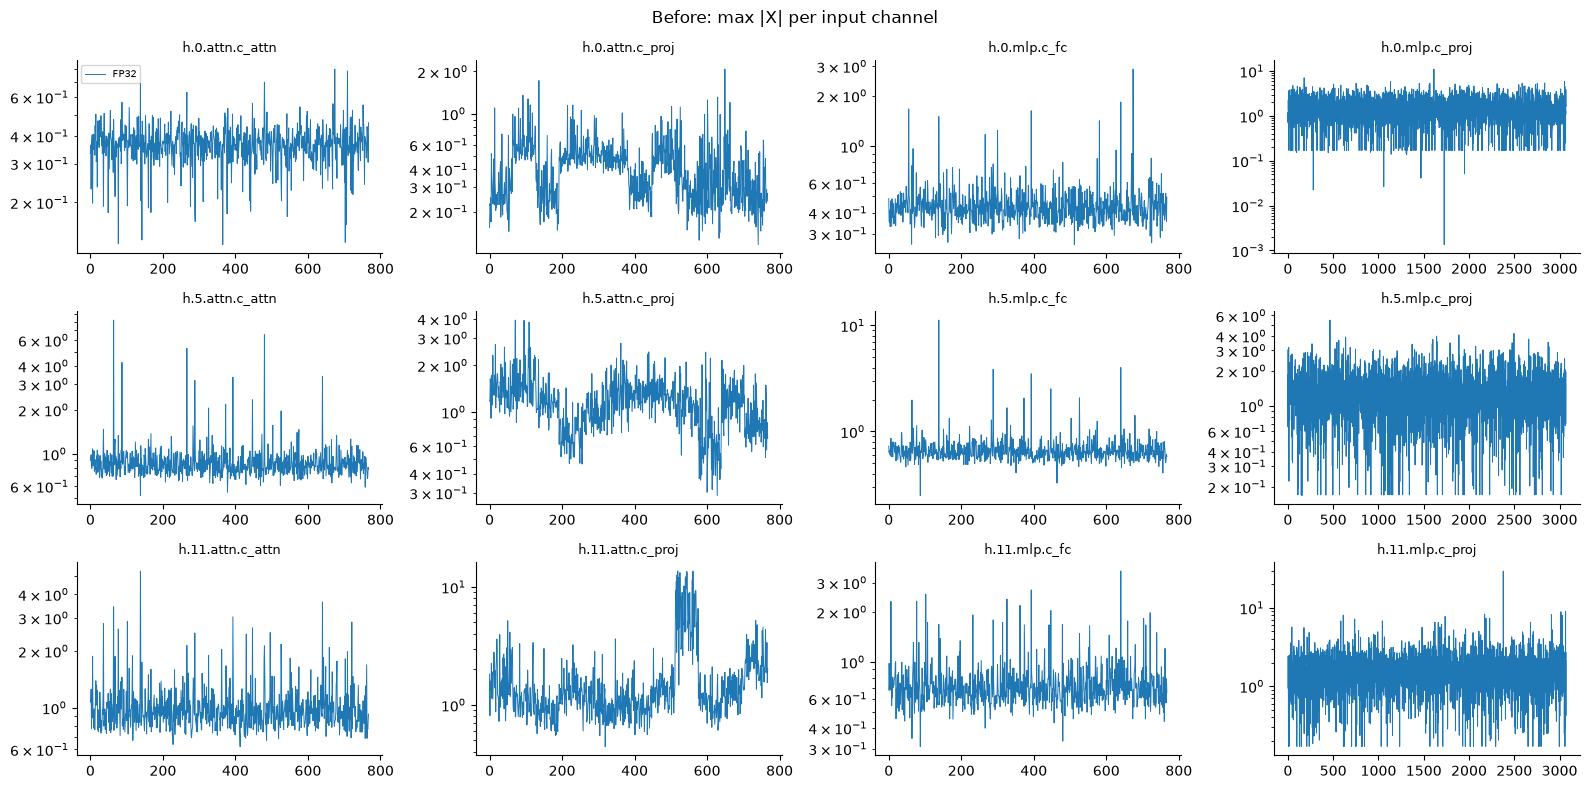

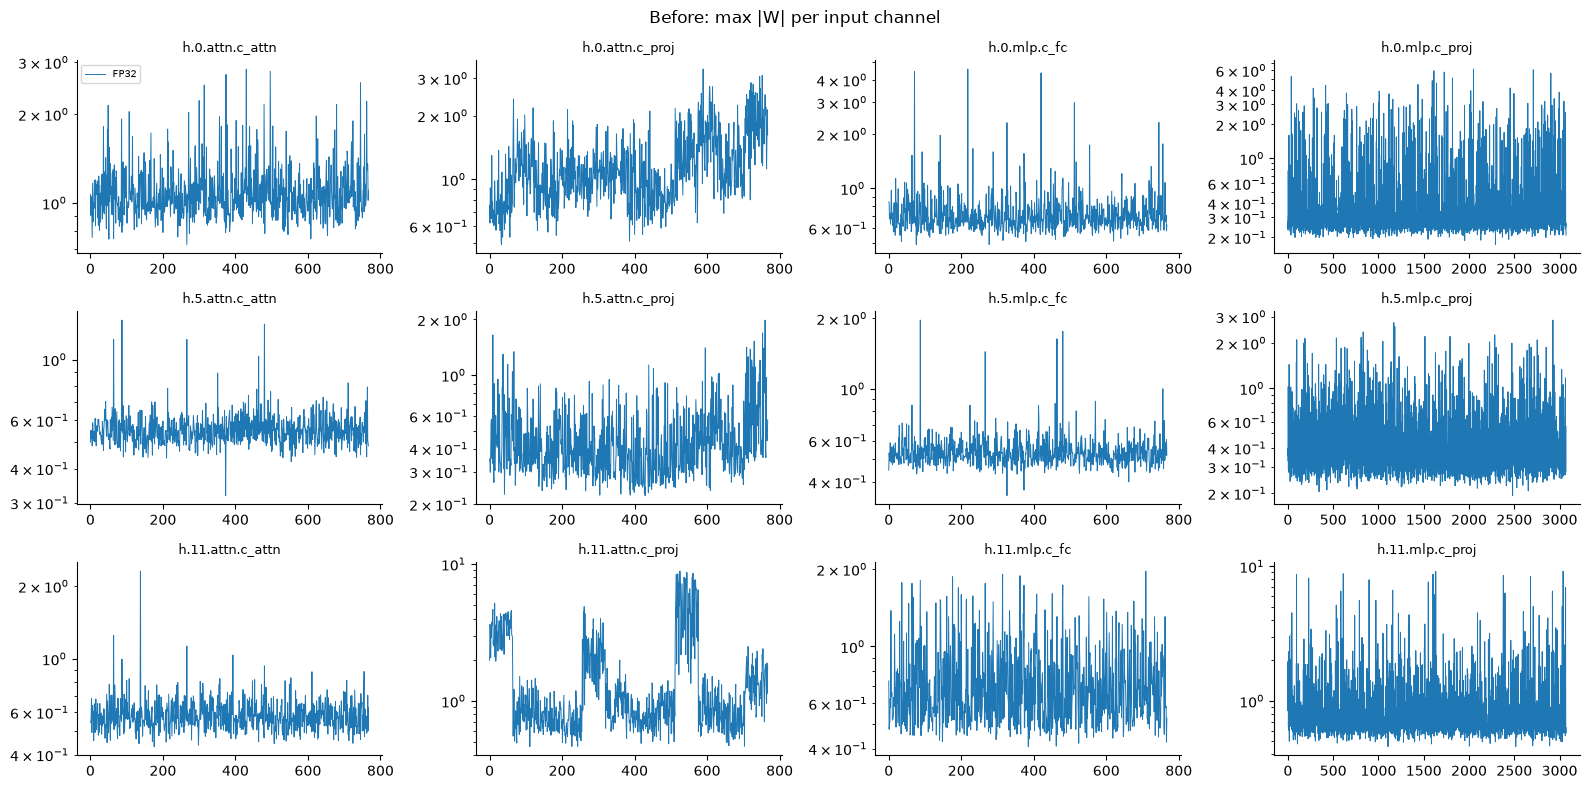

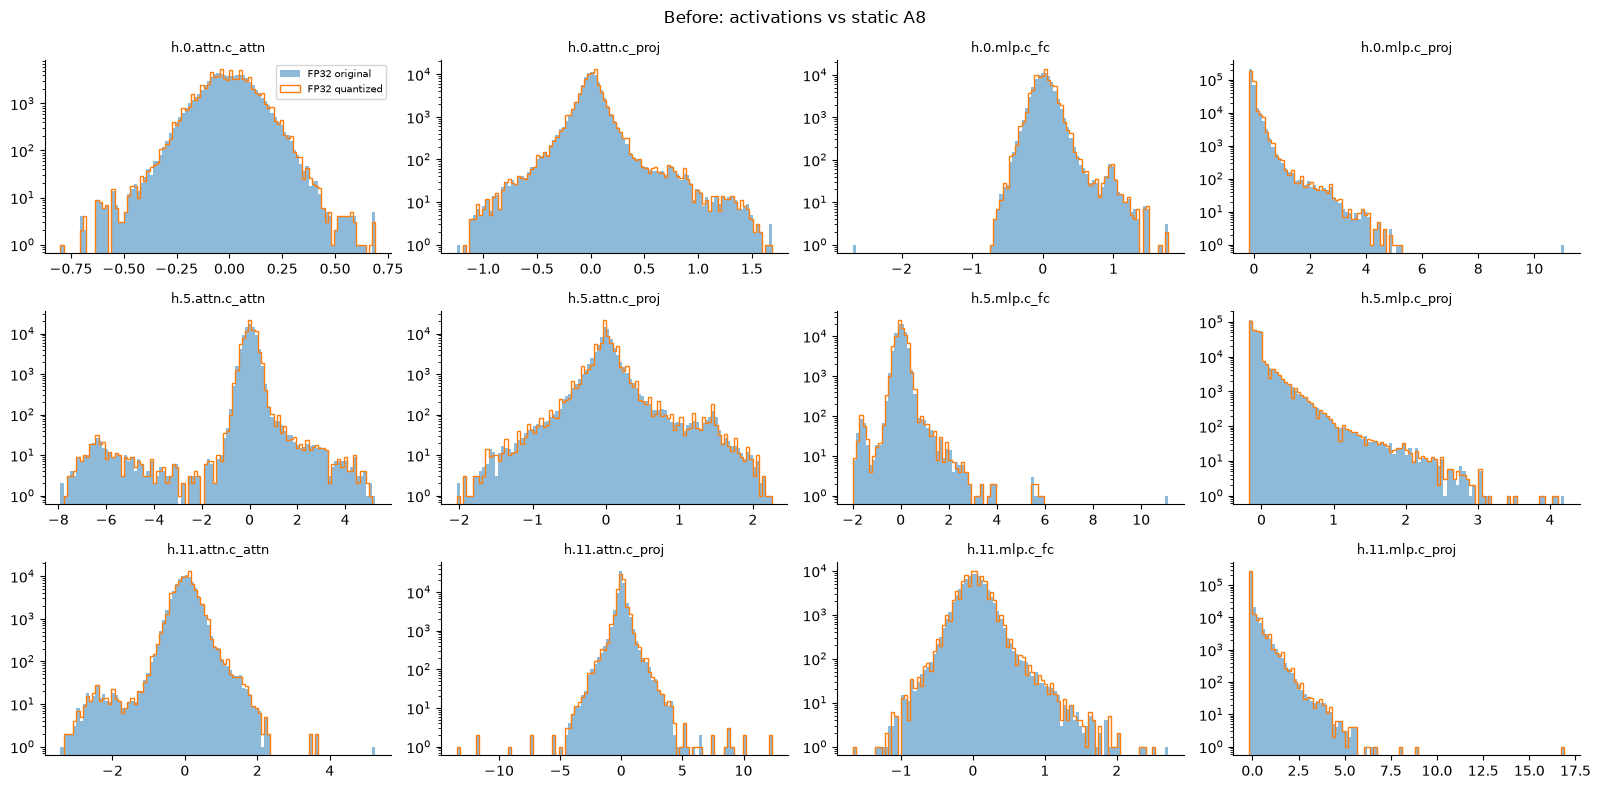

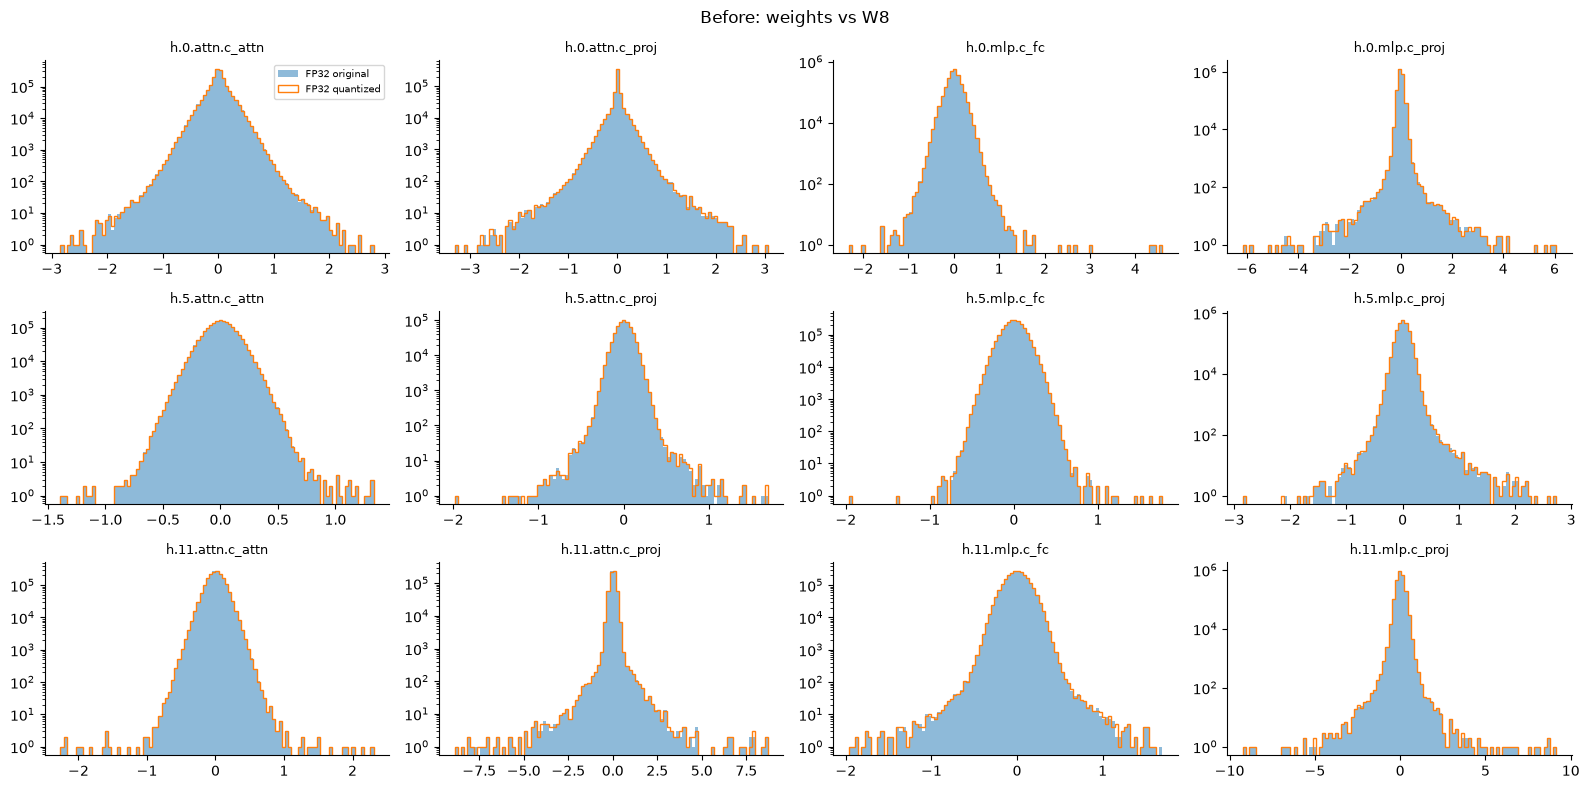


=== Equivalence (smoothed vs original, before quantization) ===


,max |Δ logits|,relative error
alpha,,
0.25,0.000916,6.057909e-07
0.50,0.000504,4.814282e-07
0.75,0.000763,5.724883e-07



=== α selection (validation PPL) ===


,val PPL α=0.25,val PPL α=0.5,val PPL α=0.75,chosen α
Static W8A8,1044.053,81.231,72.791,0.75
Dynamic W8A8,768.496,80.994,72.746,0.75
Static W4A8,1323.286,152.524,191.906,0.50
Dynamic W4A8,992.633,148.962,197.847,0.50


=== SmoothQuant vs FP32 (test split; quantization SIMULATED on mps) ===


,accuracy_%,nll,ppl,ΔPPL,unique_params_M,serialized_MB,packed_size_MB (theory),GMACs,GFLOPs,latency_mean_ms,latency_std_ms,seq_per_s,tokens_per_s,peak_gpu_alloc_MB,peak_process_rss_MB,cpu_util_%_one_core,energy_mJ
FP32 baseline,29.284,4.273,71.763,0.000,124.44,497.803,NaN,16.114,32.228,13.538,0.357,73.863,9454.520,524.367,1394.901,41.2,unavailable
SmoothQuant Static W8A8,29.168,4.286,72.657,0.894,124.44,243.560,243.472,16.114,32.228,15.878,0.390,62.981,8061.548,609.818,1394.901,40.7,unavailable
SmoothQuant Dynamic W8A8,29.149,4.285,72.579,0.817,124.44,243.533,243.471,16.114,32.228,18.129,2.545,55.159,7060.379,609.818,1394.901,55.7,unavailable
SmoothQuant Static W4A8,21.897,5.023,151.791,80.029,124.44,243.560,201.004,16.114,32.228,16.046,1.505,62.319,7976.848,609.818,1394.901,41.7,unavailable
SmoothQuant Dynamic W4A8,22.141,4.999,148.256,76.494,124.44,243.533,201.004,16.114,32.228,17.599,0.570,56.823,7273.289,609.818,1394.901,53.5,unavailable



=== Integer-path check (block 0 attn.c_attn) ===


,max |acc| (< 2^31),max |Y_int − Y_sim|
Static W8A8,238263.0,0.000008
Dynamic W8A8,244981.0,0.000008
Static W4A8,10352.0,0.000007
Dynamic W4A8,10604.0,0.000007



=== Mean layer-wise normalized error (32 fixed validation blocks) ===


E_W                                          E_X  \
proj         attn.c_attn attn.c_proj  mlp.c_fc mlp.c_proj attn.c_attn   
config                                                                  
Static W8A8     2.28e-04    1.08e-04  1.95e-04   5.45e-04    3.13e-04   
Dynamic W8A8    2.28e-04    1.08e-04  1.95e-04   5.45e-04    2.77e-04   
Static W4A8     3.24e-02    2.84e-02  2.81e-02   4.34e-02    9.14e-04   
Dynamic W4A8    3.24e-02    2.84e-02  2.81e-02   4.34e-02    8.85e-04   

                                               
proj         attn.c_proj  mlp.c_fc mlp.c_proj  
config                                         
Static W8A8     6.26e-04  2.94e-04   1.59e-03  
Dynamic W8A8    6.18e-04  2.75e-04   1.52e-03  
Static W4A8     1.35e-03  9.72e-04   1.35e-02  
Dynamic W4A8    1.04e-03  9.07e-04   1.21e-02

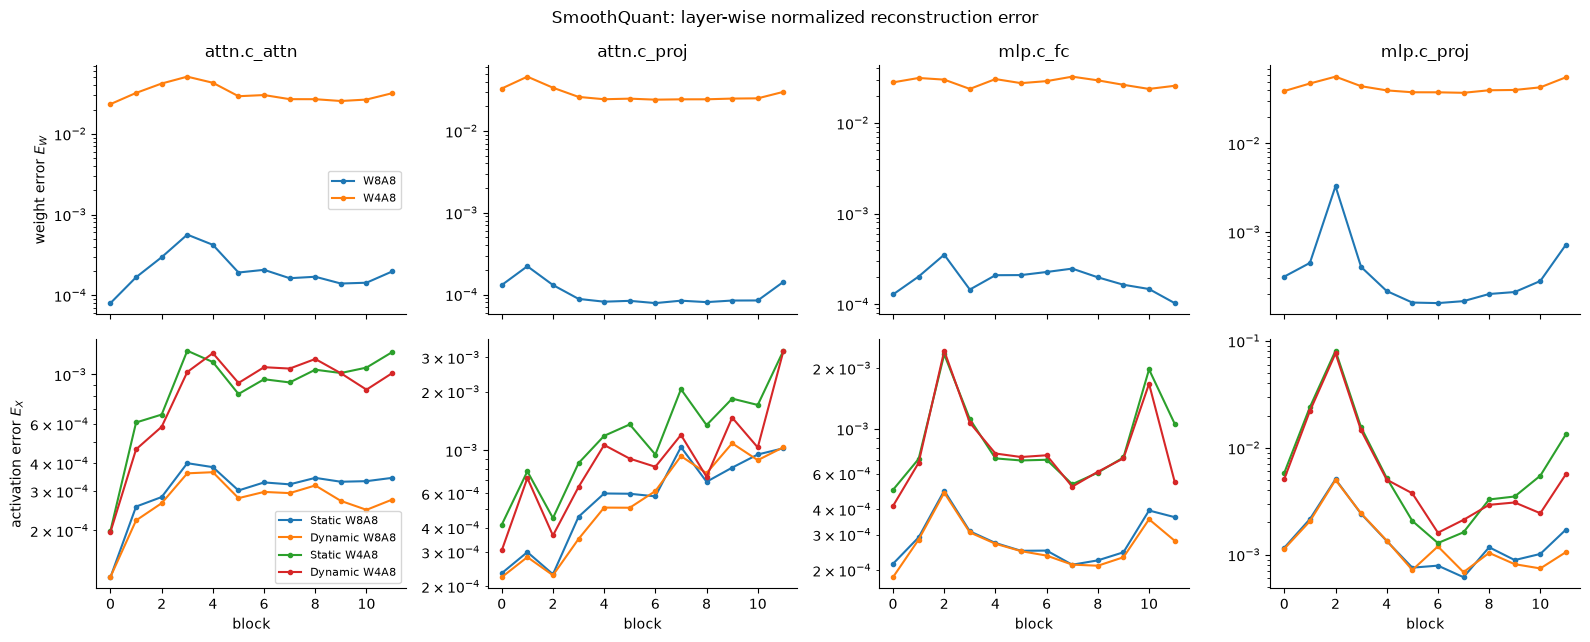


=== AFTER smoothing (α = 0.75) ===


,X max,X p99,X top/median ch,W max,W p99,W top/median ch,static clip %,E_X static,E_X dynamic,E_W W8,E_W W4
layer,,,,,,,,,,,
h.0.attn.c_attn,1.0893,0.6505,1.6432,1.3046,0.3621,2.2500,0.0000,0.0001,0.0001,0.0001,0.0262
h.0.attn.c_proj,1.4881,0.6782,2.3196,2.2471,0.4024,3.3018,0.0004,0.0002,0.0003,0.0001,0.0419
h.0.mlp.c_fc,1.2277,0.6135,2.0116,2.3077,0.3044,4.8554,0.0000,0.0002,0.0002,0.0001,0.0394
h.0.mlp.c_proj,2.6445,0.5757,4.3850,24.8422,0.6695,32.8453,0.0000,0.0012,0.0010,0.0003,0.0586
h.5.attn.c_attn,1.7301,0.6142,2.4823,5.6201,0.4454,8.5534,0.0000,0.0003,0.0003,0.0002,0.0491
h.5.attn.c_proj,1.6677,0.5511,2.7068,2.8099,0.4848,3.9341,0.0003,0.0006,0.0007,0.0001,0.0276
h.5.mlp.c_fc,1.6383,0.5554,2.5143,4.3872,0.3644,8.4358,0.0001,0.0002,0.0002,0.0002,0.0685
h.5.mlp.c_proj,1.7228,0.3823,2.9113,4.9364,0.6408,5.9571,0.0000,0.0007,0.0008,0.0002,0.0520
h.11.attn.c_attn,1.8716,0.6067,2.6145,6.5439,0.5290,8.6456,0.0001,0.0003,0.0003,0.0002,0.0584


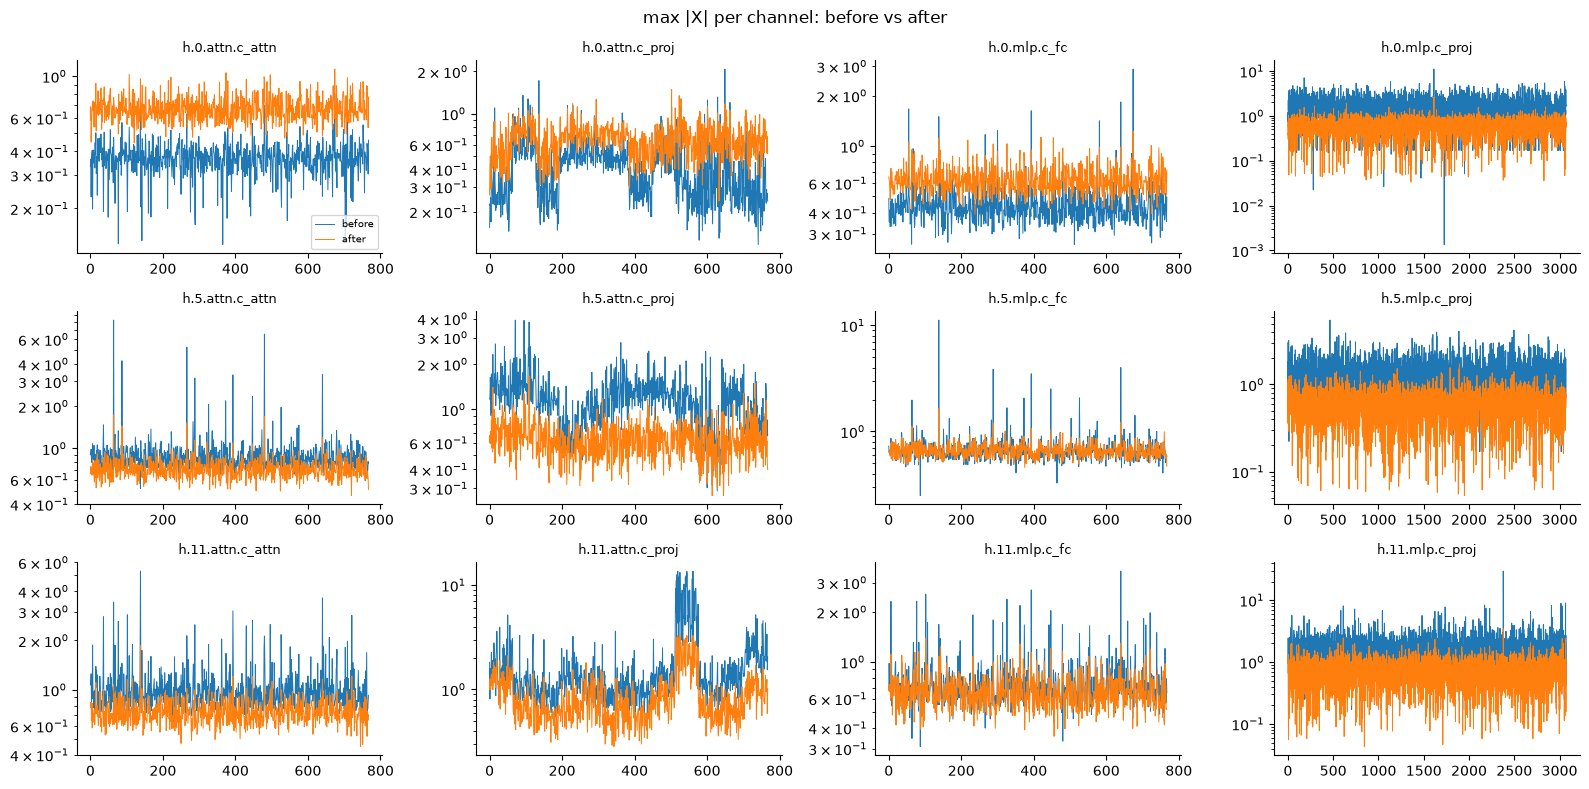

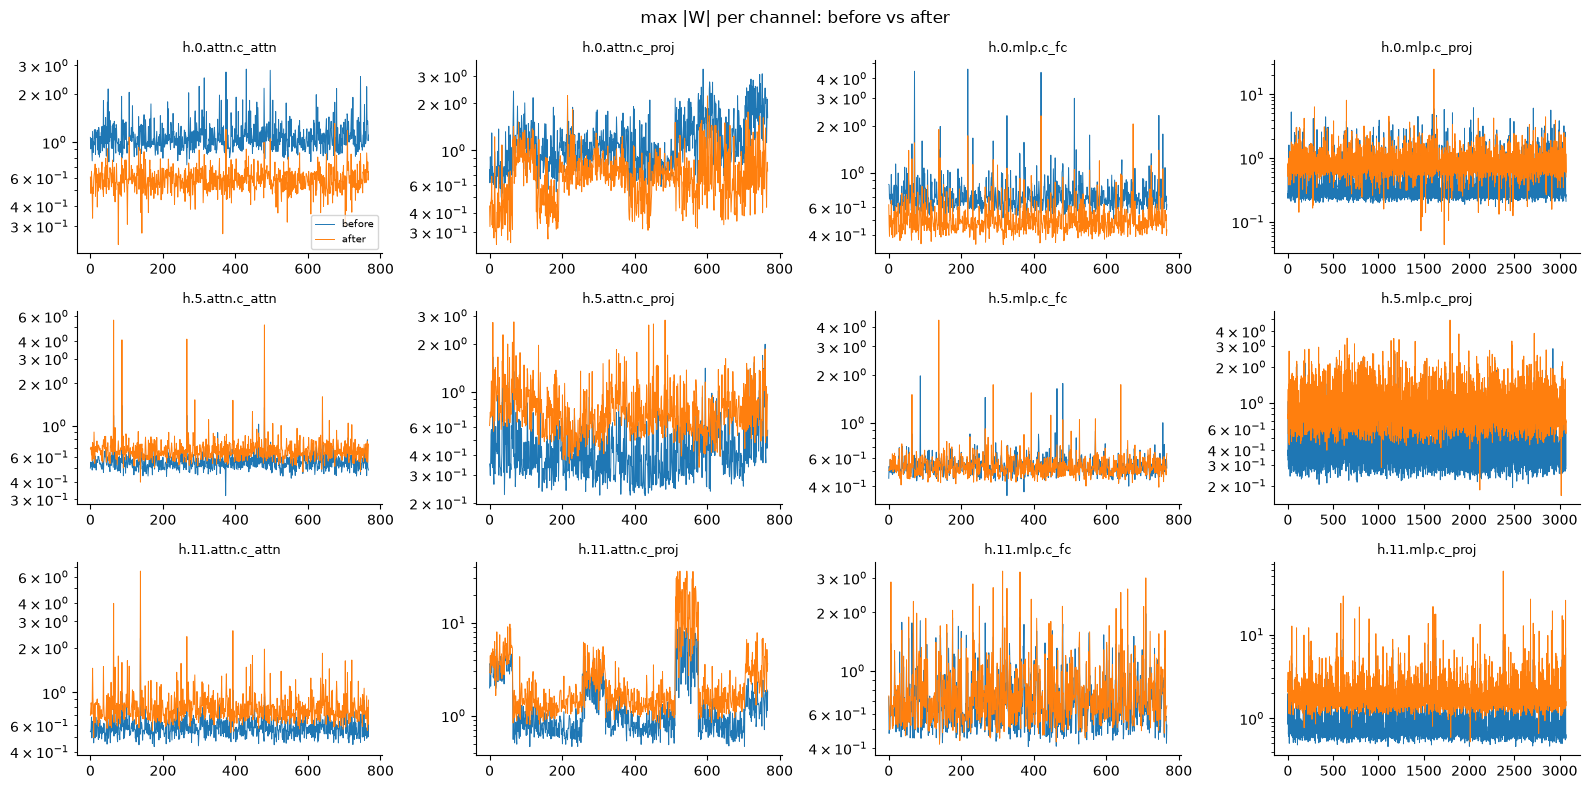

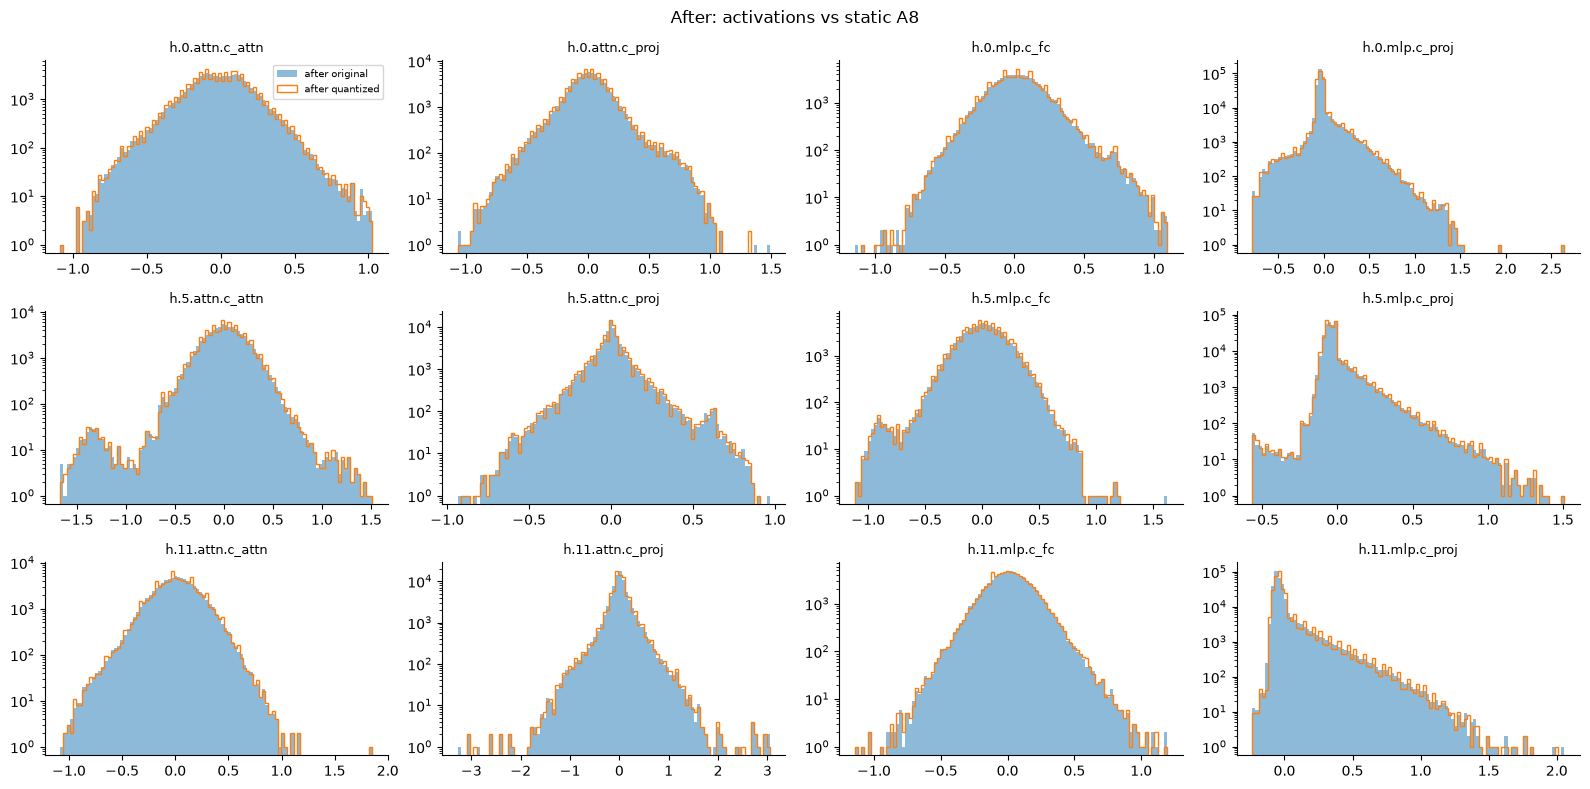

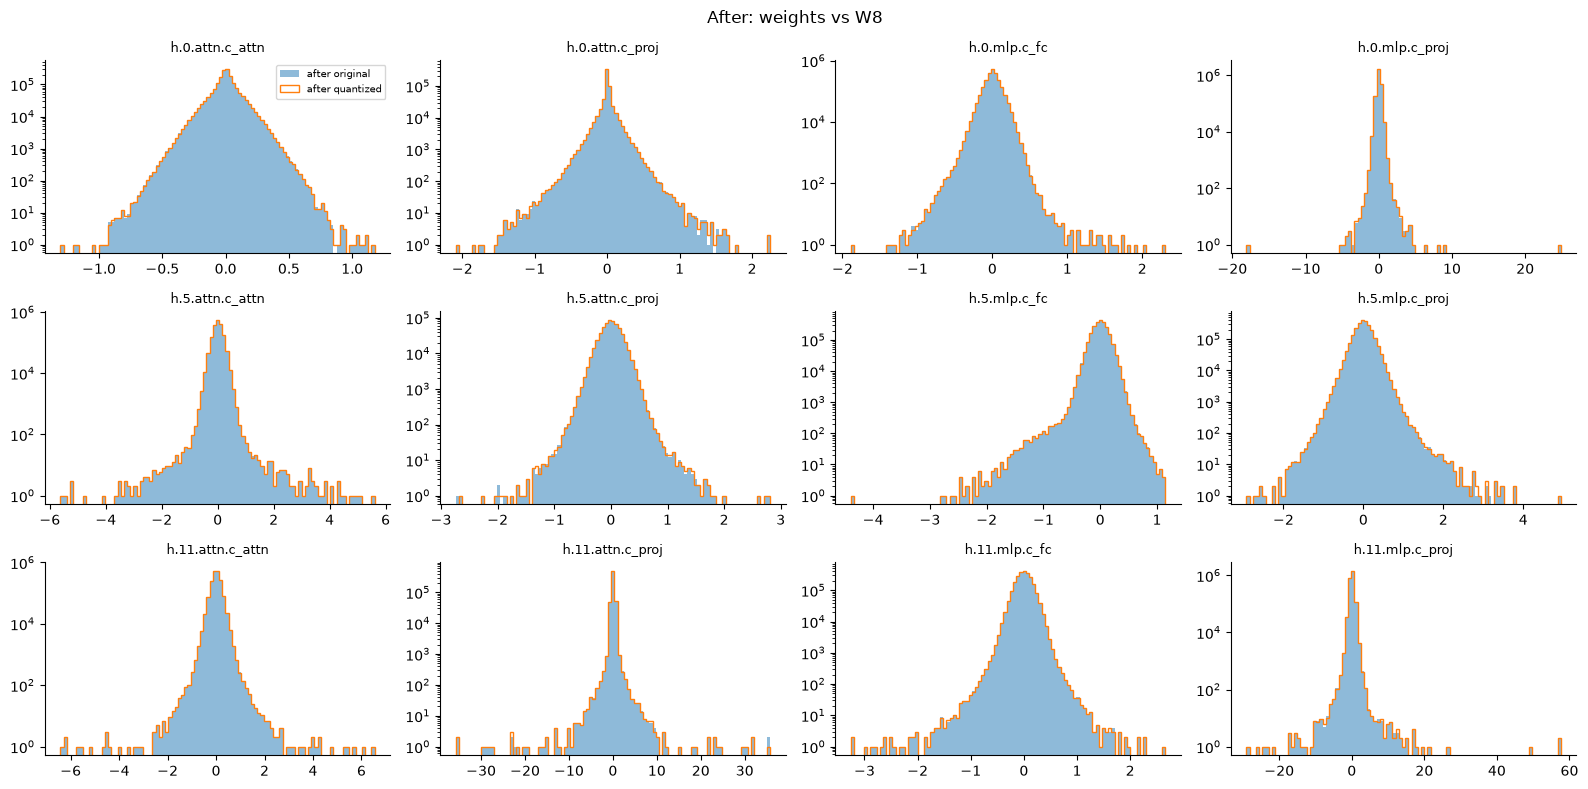


=== Before vs after ===


E_W W4          E_W W8         E_X dynamic          \
                   after  before   after  before       after  before   
layer                                                                  
h.0.attn.c_attn   0.0262  0.0300  0.0001  0.0001      0.0001  0.0002   
h.0.attn.c_proj   0.0419  0.0292  0.0001  0.0001      0.0003  0.0006   
h.0.mlp.c_fc      0.0394  0.0276  0.0001  0.0001      0.0002  0.0013   
h.0.mlp.c_proj    0.0586  0.0600  0.0003  0.0004      0.0010  0.0037   
h.5.attn.c_attn   0.0491  0.0230  0.0002  0.0001      0.0003  0.0015   
h.5.attn.c_proj   0.0276  0.0241  0.0001  0.0001      0.0007  0.0007   
h.5.mlp.c_fc      0.0685  0.0203  0.0002  0.0001      0.0002  0.0041   
h.5.mlp.c_proj    0.0520  0.0435  0.0002  0.0001      0.0008  0.0014   
h.11.attn.c_attn  0.0584  0.0275  0.0002  0.0001      0.0003  0.0010   
h.11.attn.c_proj  0.0347  0.0280  0.0001  0.0001      0.0010  0.0039   
h.11.mlp.c_fc     0.0337  0.0222  0.0001  0.0001      0.0003  0.0011   
h.11.mlp.c_proj   0.0944  0.0730  0.0007  0.0004      0.0014  0.0156   

                 E_X static            W max           W p99          \
                      after  before    after  before   after  before   
layer                                                                  
h.0.attn.c_attn      0.0001  0.0003   1.3046  2.8436  0.3621  0.6634   
h.0.attn.c_proj      0.0002  0.0006   2.2471  3.3171  0.4024  0.5910   
h.0.mlp.c_fc         0.0002  0.0013   2.3077  4.5877  0.3044  0.4162   
h.0.mlp.c_proj       0.0012  0.0051  24.8422  6.1433  0.6695  0.2337   
h.5.attn.c_attn      0.0003  0.0016   5.6201  1.3924  0.4454  0.3551   
h.5.attn.c_proj      0.0006  0.0012   2.8099  1.9833  0.4848  0.2544   
h.5.mlp.c_fc         0.0002  0.0043   4.3872  1.9646  0.3644  0.3412   
h.5.mlp.c_proj       0.0007  0.0013   4.9364  2.8407  0.6408  0.2648   
h.11.attn.c_attn     0.0003  0.0014   6.5439  2.3071  0.5290  0.3652   
h.11.attn.c_proj     0.0010  0.0039  35.7554  8.8818  0.8691  0.4598   
h.11.mlp.c_fc        0.0004  0.0014   3.2511  1.9649  0.4041  0.3420   
h.11.mlp.c_proj      0.0017  0.0137  57.5769  9.2115  1.3322  0.5406   

                 W top/median ch            X max            X p99          \
                           after   before   after   before   after  before   
layer                                                                        
h.0.attn.c_attn           2.2500   2.7545  1.0893   0.8031  0.6505  0.3182   
h.0.attn.c_proj           3.3018   3.1059  1.4881   2.0790  0.6782  0.7056   
h.0.mlp.c_fc              4.8554   6.7936  1.2277   2.8819  0.6135  0.4502   
h.0.mlp.c_proj           32.8453  21.4955  2.6445  11.0651  0.5757  0.7078   
h.5.attn.c_attn           8.5534   2.5477  1.7301   8.2153  0.6142  0.9561   
h.5.attn.c_proj           3.9341   5.0760  1.6677   3.9123  0.5511  1.2341   
h.5.mlp.c_fc              8.4358   3.7638  1.6383  11.2273  0.5554  0.6568   
h.5.mlp.c_proj            5.9571   7.5543  1.7228   5.4699  0.3823  0.6728   
h.11.attn.c_attn          8.6456   4.0273  1.8716   5.3086  0.6067  0.9741   
h.11.attn.c_proj         21.2986   9.3816  3.2947  13.6274  0.8665  1.8669   
h.11.mlp.c_fc             4.6697   3.1010  1.3817   3.5178  0.5157  0.6259   
h.11.mlp.c_proj          34.0386  12.9010  3.4647  29.4838  0.5433  1.2768   

                 X top/median ch          static clip %           
                           after   before         after   before  
layer                                                             
h.0.attn.c_attn           1.6432   2.1747        0.0000   0.0000  
h.0.attn.c_proj           2.3196   5.2515        0.0004   0.0001  
h.0.mlp.c_fc              2.0116   6.8148        0.0000   0.0000  
h.0.mlp.c_proj            4.3850   8.1929        0.0000   0.0000  
h.5.attn.c_attn           2.4823   9.8571        0.0000   0.0000  
h.5.attn.c_proj           2.7068   3.4236        0.0003   0.0000  
h.5.mlp.c_fc              2.5143  17.5751        0.0001   0.0000  
h.5.mlp.c_proj 


=== Linear PTQ vs SmoothQuant ===


test PPL              mean E_W              mean E_X  \
method            Linear SmoothQuant    Linear SmoothQuant    Linear   
config                                                                 
Static W8A8    76.346031   72.656916  0.000120    0.000269  0.005599   
Dynamic W8A8   75.467346   72.579318  0.000120    0.000269  0.005077   
Static W4A8   125.134589  151.791380  0.032174    0.033059  0.005825   
Dynamic W4A8  121.497736  148.256434  0.032174    0.033059  0.005400   

                          
method       SmoothQuant  
config                    
Static W8A8     0.000706  
Dynamic W8A8    0.000672  
Static W4A8     0.004185  
Dynamic W4A8    0.003725

In [73]:
print("=== BEFORE smoothing (blocks 0, 5, 11) ===")
display(before_df.round(4))
plot_grid([("FP32", before)], "x_ch", "Before: max |X| per input channel", "figures/t22_before_x_ch.png")
plot_grid([("FP32", before)], "w_ch", "Before: max |W| per input channel", "figures/t22_before_w_ch.png")
plot_grid([("FP32", before)], "x", "Before: activations vs static A8", "figures/t22_before_x_hist.png")
plot_grid([("FP32", before)], "w", "Before: weights vs W8", "figures/t22_before_w_hist.png")

print("\n=== Equivalence (smoothed vs original, before quantization) ===")
display(equiv_df)

print("\n=== α selection (validation PPL) ===")
display(alpha_df.round(3))

show_method(SQ, "SmoothQuant", "figures/t22_layer_errors.png")

print(f"\n=== AFTER smoothing (α = {A}) ===")
display(after_df.round(4))
plot_grid([("before", before), ("after", after)], "x_ch", "max |X| per channel: before vs after",
          "figures/t22_x_ch_compare.png")
plot_grid([("before", before), ("after", after)], "w_ch", "max |W| per channel: before vs after",
          "figures/t22_w_ch_compare.png")
plot_grid([("after", after)], "x", "After: activations vs static A8", "figures/t22_after_x_hist.png")
plot_grid([("after", after)], "w", "After: weights vs W8", "figures/t22_after_w_hist.png")

print("\n=== Before vs after ===")
display(pd.concat({"before": before_df, "after": after_df}, axis=1)
          .swaplevel(axis=1).sort_index(axis=1).round(4))

print("\n=== Linear PTQ vs SmoothQuant ===")
display(compare_methods(("Linear", PTQ), ("SmoothQuant", SQ)))

## Task 2.3 — GPTQ and Reconstruction Analysis

In [74]:
# ---------- Method 3: GPTQ ----------
@torch.no_grad()
def gptq_layer(W, H, bits, block=128, damp=0.01):
    """Round columns one by one; push each error onto the not-yet-rounded columns (same layer).
    W: Conv1D weight (in, out). Same scales/grid as linear PTQ."""
    _, S = quantize_weight(W, bits)                         # same per-column scales as RTN
    W, S, Qb = W.t().clone(), S.t(), 2 ** (bits - 1) - 1    # (out, in): columns = input channels
    H = H.cpu().double()
    H[torch.diag(H) == 0, torch.diag(H) == 0] = 1           # dead inputs
    H += damp * torch.diag(H).mean() * torch.eye(len(H), dtype=H.dtype)            # λ = 1% mean diag
    Hinv = torch.linalg.cholesky(torch.cholesky_inverse(torch.linalg.cholesky(H)), upper=True).float()
    Q = torch.zeros_like(W)
    for a in range(0, W.size(1), block):                    # blocks of 128 columns
        b = min(a + block, W.size(1))
        E = torch.zeros(W.size(0), b - a)
        for i in range(a, b):
            Q[:, i] = torch.clamp(torch.round(W[:, i] / S[:, 0]), -Qb, Qb)          # round column i
            E[:, i - a] = (W[:, i] - Q[:, i] * S[:, 0]) / Hinv[i, i]
            W[:, i:b] -= E[:, i - a:i - a + 1] @ Hinv[i:i + 1, i:b]                 # fix rest of block
        W[:, b:] -= E @ Hinv[a:b, b:]                                               # fix later blocks
    return Q.t(), S.t()

@torch.no_grad()
def gptq_weights(bits):
    """Layer by layer (execution order). Each layer's H uses inputs from already-quantized layers.
    Also compares RTN vs GPTQ errors on identical validation inputs."""
    if ("gptq", bits) in _CACHE: return _CACHE[("gptq", bits)]
    model, new_w, rows, t0, peak = load_fp32_model(), {}, [], time.perf_counter(), 0
    err = lambda A, B: ((A - B).pow(2).sum() / (A.pow(2).sum() + EPS)).item()
    for name in proj_names(model):
        conv, st = model.get_submodule(name), {"H": 0, "n": 0, "val": [], "calib": True}
        def hook(m, inp):
            x = inp[0].reshape(-1, inp[0].size(-1)).float()
            if st["calib"]: st["H"] = st["H"] + 2 * x.t() @ x; st["n"] += len(x)
            else: st["val"].append(x.cpu())
        h = conv.register_forward_pre_hook(hook)
        run_blocks(model, calib_blocks); st["calib"] = False; run_blocks(model, ERR_BLOCKS); h.remove()
        W = conv.weight.data.float().cpu()
        q, S = gptq_layer(W, st["H"] / st["n"], bits)
        q_r, S_r = quantize_weight(W, bits)                          # RTN for comparison
        X = torch.cat(st["val"])
        rows.append({"proj": name.split(".", 3)[3],
                     "E_W RTN": err(W, q_r * S_r), "E_W GPTQ": err(W, q * S),
                     "E_out RTN": err(X @ W, X @ (q_r * S_r)), "E_out GPTQ": err(X @ W, X @ (q * S))})
        conv.weight.data.copy_((q * S).to(DEVICE))                  # next layers see quantized weights
        new_w[name] = (q, S)
        peak = max(peak, gpu_mem())
    cost = {"GPTQ time (s)": time.perf_counter() - t0, "peak GPU alloc (MB)": peak / 1e6,
            "peak process RSS (MB)": psutil.Process().memory_info().rss / 1e6}
    _CACHE[("gptq", bits)] = (new_w, pd.DataFrame(rows), cost)
    return _CACHE[("gptq", bits)]

def gptq_weight_model(bits):
    """FP32 model with GPTQ weights (activations not quantized) — for static calibration."""
    model = load_fp32_model()
    for name, (q, S) in gptq_weights(bits)[0].items():
        model.get_submodule(name).weight.data.copy_((q * S).to(DEVICE))
    return model

def run_gptq(name, bits, mode):
    """GPTQ weights + 2.1 A8 quantizer; static ranges calibrated on the GPTQ-weight model."""
    ranges = calibrate_ranges(gptq_weight_model(bits), calib_blocks) if mode == "static" else None
    model = quantize_model(load_fp32_model(), bits, mode, ranges, new_weights=gptq_weights(bits)[0])
    return evaluate_config(model, f"GPTQ {name}", bits)

## calling functions

In [75]:
set_seed()
before_df, _ = distribution_analysis(load_fp32_model(), fp32_ranges())     # original model, as in 2.2
GPTQ = run_all(run_gptq)
after_a8 = {b: distribution_analysis(m := gptq_weight_model(b), calibrate_ranges(m, calib_blocks))[0]
            for b in (8, 4)}                                               # E_X + clipping after A8

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6473.30it/s]
USDT:2026-10-21 21:08:30 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 21:08:30 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_gptq         Static W8A8   PPL    76.20 | Acc 28.54% | 124s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 4376.37it/s]
USDT:2026-10-21 21:09:02 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 21:09:02 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_gptq         Dynamic W8A8  PPL    75.36 | Acc 28.76% | 32s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7347.45it/s]
USDT:2026-10-21 21:11:09 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 21:11:09 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_gptq         Static W4A8   PPL    87.77 | Acc 27.12% | 127s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6872.56it/s]
USDT:2026-10-21 21:11:41 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-21 21:11:41 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


run_gptq         Dynamic W4A8  PPL    86.12 | Acc 27.32% | 32s


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 13254.41it/s]


### results

=== Before quantization (original model) ===


,X max,X p99,X top/median ch,W max,W p99,W top/median ch,static clip %,E_X static,E_X dynamic,E_W W8,E_W W4
layer,,,,,,,,,,,
h.0.attn.c_attn,0.8031,0.3182,2.1747,2.8436,0.6634,2.7545,0.0000,0.0003,0.0002,0.0001,0.0300
h.0.attn.c_proj,2.0790,0.7056,5.2515,3.3171,0.5910,3.1059,0.0001,0.0006,0.0006,0.0001,0.0292
h.0.mlp.c_fc,2.8819,0.4502,6.8148,4.5877,0.4162,6.7936,0.0000,0.0013,0.0013,0.0001,0.0276
h.0.mlp.c_proj,11.0651,0.7078,8.1929,6.1433,0.2337,21.4955,0.0000,0.0051,0.0037,0.0004,0.0600
h.5.attn.c_attn,8.2153,0.9561,9.8571,1.3924,0.3551,2.5477,0.0000,0.0016,0.0015,0.0001,0.0230
h.5.attn.c_proj,3.9123,1.2341,3.4236,1.9833,0.2544,5.0760,0.0000,0.0012,0.0007,0.0001,0.0241
h.5.mlp.c_fc,11.2273,0.6568,17.5751,1.9646,0.3412,3.7638,0.0000,0.0043,0.0041,0.0001,0.0203
h.5.mlp.c_proj,5.4699,0.6728,4.6233,2.8407,0.2648,7.5543,11.0793,0.0013,0.0014,0.0001,0.0435
h.11.attn.c_attn,5.3086,0.9741,5.6513,2.3071,0.3652,4.0273,0.0000,0.0014,0.0010,0.0001,0.0275



=== GPTQ time and memory ===


,W8,W4
GPTQ time (s),89.83,92.80
peak GPU alloc (MB),2354.54,2354.54
peak process RSS (MB),864.93,349.72



=== RTN vs GPTQ: weight error and layer-output error (identical validation inputs) ===


E_W RTN  E_W GPTQ E_out RTN E_out GPTQ
   proj                                                
W8 attn.c_attn  7.81e-05  1.25e-04  4.87e-05   1.57e-05
   attn.c_proj  8.31e-05  1.34e-04  1.64e-04   4.72e-05
   mlp.c_fc     6.72e-05  1.06e-04  2.38e-05   9.77e-06
   mlp.c_proj   2.50e-04  4.03e-04  2.67e-04   1.03e-04
W4 attn.c_attn  2.56e-02  3.98e-02  1.45e-02   5.12e-03
   attn.c_proj  2.65e-02  4.23e-02  5.76e-02   1.50e-02
   mlp.c_fc     2.17e-02  3.38e-02  7.82e-03   3.24e-03
   mlp.c_proj   5.49e-02  8.60e-02  7.69e-02   2.74e-02

... (2 outputs left out)


=== Integer-path check (block 0 attn.c_attn) ===


,max |acc| (< 2^31),max |Y_int − Y_sim|
Static W8A8,181693.0,0.000009
Dynamic W8A8,193635.0,0.000008
Static W4A8,9973.0,0.000007
Dynamic W4A8,10629.0,0.000006



=== Mean layer-wise normalized error (32 fixed validation blocks) ===


E_W                                          E_X  \
proj         attn.c_attn attn.c_proj  mlp.c_fc mlp.c_proj attn.c_attn   
config                                                                  
Static W8A8     1.25e-04    1.34e-04  1.06e-04   4.03e-04    1.43e-03   
Dynamic W8A8    1.25e-04    1.34e-04  1.06e-04   4.03e-04    1.29e-03   
Static W4A8     3.98e-02    4.23e-02  3.38e-02   8.60e-02    1.47e-03   
Dynamic W4A8    3.98e-02    4.23e-02  3.38e-02   8.60e-02    1.33e-03   

                                               
proj         attn.c_proj  mlp.c_fc mlp.c_proj  
config                                         
Static W8A8     1.45e-03  3.89e-03   1.56e-02  
Dynamic W8A8    1.13e-03  3.73e-03   1.46e-02  
Static W4A8     1.48e-03  3.92e-03   1.57e-02  
Dynamic W4A8    1.08e-03  3.74e-03   1.46e-02

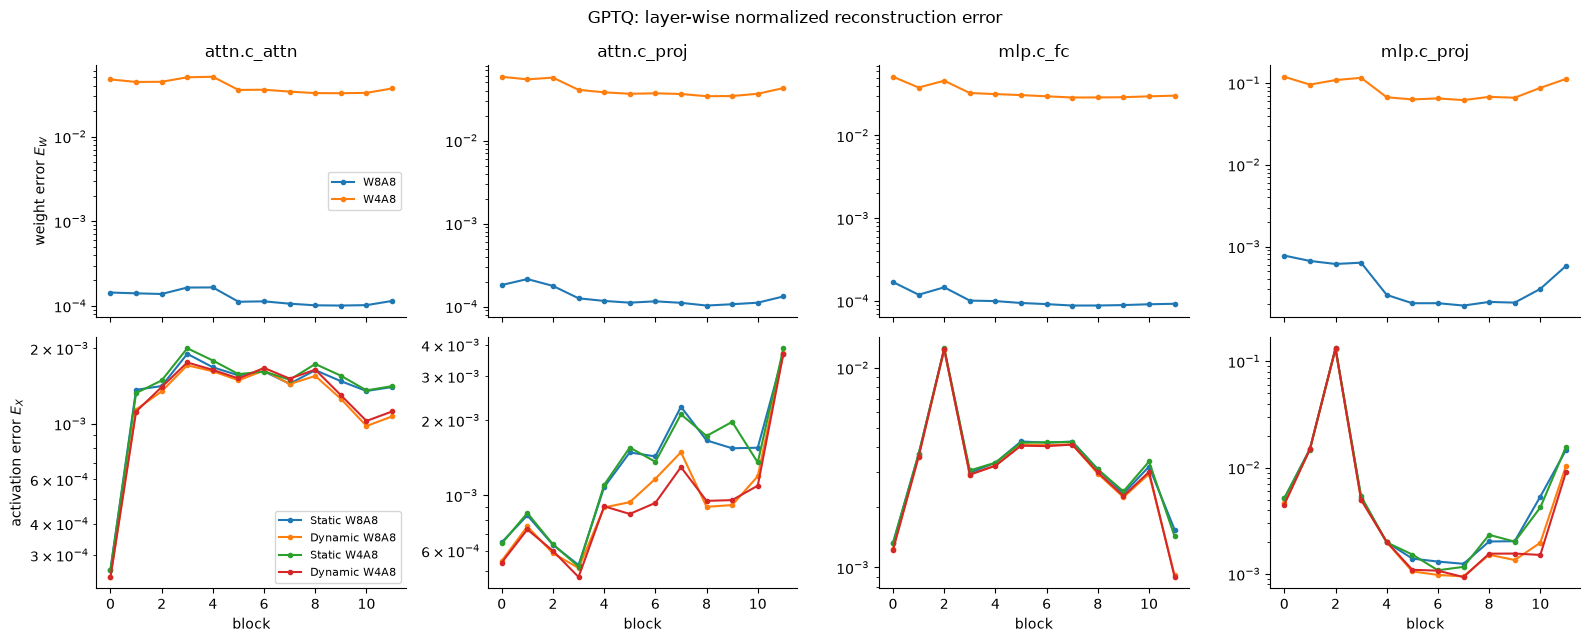


=== After A8 on GPTQ weights: activation error and clipping ===


W8                                   W4  \
                 static clip % E_X static E_X dynamic static clip %   
layer                                                                 
h.0.attn.c_attn         0.0000     0.0003      0.0002        0.0000   
h.0.attn.c_proj         0.0001     0.0006      0.0006        0.0001   
h.0.mlp.c_fc            0.0000     0.0013      0.0013        0.0000   
h.0.mlp.c_proj          0.0000     0.0051      0.0037        0.0000   
h.5.attn.c_attn         0.0000     0.0016      0.0015        0.0000   
h.5.attn.c_proj         0.0000     0.0012      0.0007        0.0000   
h.5.mlp.c_fc            0.0000     0.0043      0.0041        0.0000   
h.5.mlp.c_proj         10.1768     0.0013      0.0013       16.8181   
h.11.attn.c_attn        0.0001     0.0014      0.0010        0.0000   
h.11.attn.c_proj        0.0001     0.0039      0.0039        0.0000   
h.11.mlp.c_fc           0.0000     0.0014      0.0011        0.0000   
h.11.mlp.c_proj        41.2766     0.0137      0.0157       42.7451   

                                         
                 E_X static E_X dynamic  
layer                                    
h.0.attn.c_attn      0.0003      0.0002  
h.0.attn.c_proj      0.0006      0.0006  
h.0.mlp.c_fc         0.0013      0.0013  
h.0.mlp.c_proj       0.0051      0.0035  
h.5.attn.c_attn      0.0016      0.0015  
h.5.attn.c_proj      0.0013      0.0008  
h.5.mlp.c_fc         0.0042      0.0041  
h.5.mlp.c_proj       0.0014      0.0015  
h.11.attn.c_attn     0.0014      0.0010  
h.11.attn.c_proj     0.0040      0.0040  
h.11.mlp.c_fc        0.0013      0.0011  
h.11.mlp.c_proj      0.0144      0.0150


=== Linear PTQ vs SmoothQuant vs GPTQ ===


test PPL                          mean E_W            \
method             GPTQ      Linear SmoothQuant      GPTQ    Linear   
config                                                                
Static W8A8   76.199205   76.346031   72.656916  0.000192  0.000120   
Dynamic W8A8  75.363121   75.467346   72.579318  0.000192  0.000120   
Static W4A8   87.765733  125.134589  151.791380  0.050478  0.032174   
Dynamic W4A8  86.124921  121.497736  148.256434  0.050478  0.032174   

                          mean E_X                        
method       SmoothQuant      GPTQ    Linear SmoothQuant  
config                                                    
Static W8A8     0.000269  0.005589  0.005599    0.000706  
Dynamic W8A8    0.000269  0.005186  0.005077    0.000672  
Static W4A8     0.033059  0.005628  0.005825    0.004185  
Dynamic W4A8    0.033059  0.005194  0.005400    0.003725

In [76]:
print("=== Before quantization (original model) ===")
display(before_df.round(4))

print("\n=== GPTQ time and memory ===")
display(pd.DataFrame({f"W{b}": gptq_weights(b)[2] for b in (8, 4)}).round(2))

print("\n=== RTN vs GPTQ: weight error and layer-output error (identical validation inputs) ===")
display(pd.concat({f"W{b}": gptq_weights(b)[1].groupby("proj").mean() for b in (8, 4)})
          .map(lambda v: f"{v:.2e}"))

show_method(GPTQ, "GPTQ", "figures/t23_layer_errors.png")

print("\n=== After A8 on GPTQ weights: activation error and clipping ===")
display(pd.concat({f"W{b}": d[["static clip %", "E_X static", "E_X dynamic"]]
                   for b, d in after_a8.items()}, axis=1).round(4))

print("\n=== Linear PTQ vs SmoothQuant vs GPTQ ===")
display(compare_methods(("Linear", PTQ), ("SmoothQuant", SQ), ("GPTQ", GPTQ)))

## Task 2.4 — Consolidated Results

In [77]:
# ---------- 2.4 Consolidated results ----------
METHODS = ["Linear", "SmoothQuant", "GPTQ"]

def final_table():
    """FP32 + 12 configs: accuracy, storage, compute, runtime, memory, energy, execution labels."""
    labels = [f"{m} {c}" for m in METHODS for c, _, _ in CONFIGS]
    df, th = summary_table(labels), theoretical_table()
    cfg = lambda l: l if l == "FP32 baseline" else l.split(" ", 1)[1]
    df["INT ops (G)"] = [2 * th.loc[cfg(l), "INT GMACs"] for l in df.index]       # integer mult+add
    df["FP32 FLOPs (G)"] = [2 * th.loc[cfg(l), "FP32 GMACs"] for l in df.index]   # remaining float
    df["theory arith energy (mJ)"] = [th.loc[cfg(l), "arith energy (mJ)"] for l in df.index]
    df["theory pJ/MAC"] = [th.loc[cfg(l), "pJ / MAC"] for l in df.index]
    df["theory weight DRAM (mJ)"] = [th.loc[cfg(l), "weight DRAM energy (mJ)"] for l in df.index]
    df["execution"] = ["FP32 kernels"] + ["SIMULATED: quant-dequant + FP32 matmul"] * 12
    df["4-bit packed"] = ["–"] + ["no (int8 storage)" if "W4" in l else "–" for l in labels]
    return df

def best_per_setting(df):
    """Lowest test PPL per precision/activation setting."""
    rows = []
    for c, _, _ in CONFIGS:
        sub = df[df.index.str.endswith(c)]
        best = sub["ppl"].idxmin()
        rows.append({"config": c, "best method": best.split(" ")[0], "PPL": sub.loc[best, "ppl"],
                     "ΔPPL vs FP32": sub.loc[best, "ΔPPL"], "accuracy_%": sub.loc[best, "accuracy_%"]})
    return pd.DataFrame(rows).set_index("config")

def plot_final(df, path):
    """Test PPL per config for the three methods, with the FP32 line."""
    x, w = np.arange(len(CONFIGS)), 0.27
    fig, ax = plt.subplots(figsize=(10, 4))
    for k, m in enumerate(METHODS):
        v = [df.loc[f"{m} {c}", "ppl"] for c, _, _ in CONFIGS]
        bars = ax.bar(x + (k - 1) * w, v, w, label=m)
        ax.bar_label(bars, fmt="%.1f", fontsize=8)
    ax.axhline(df.loc["FP32 baseline", "ppl"], ls="--", color="black", lw=1, label="FP32")
    ax.set_xticks(x, [c for c, _, _ in CONFIGS]); ax.set_ylabel("test perplexity (lower is better)")
    ax.legend(); ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()

### calling the main function 

In [78]:
final_df = final_table()
best_df = best_per_setting(final_df)
final_df.to_csv("results/task2_final_table.csv")

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 12624.97it/s]


### results

=== FP32 + 12 quantized configurations (test split) ===


,accuracy_%,nll,ppl,ΔPPL,unique_params_M,serialized_MB,packed_size_MB (theory),GMACs,GFLOPs,latency_mean_ms,latency_std_ms,seq_per_s,tokens_per_s,peak_gpu_alloc_MB,peak_process_rss_MB,cpu_util_%_one_core,energy_mJ,INT ops (G),FP32 FLOPs (G),theory arith energy (mJ),theory pJ/MAC,theory weight DRAM (mJ),execution,4-bit packed
FP32 baseline,29.284,4.273,71.763,0.000,124.44,497.803,NaN,16.114,32.228,13.538,0.357,73.863,9454.520,524.367,1394.901,41.2,unavailable,0.000,32.228,74.125,4.600,79.641,FP32 kernels,–
Linear Static W8A8,28.495,4.335,76.346,4.583,124.44,243.370,243.287,16.114,32.228,14.815,2.048,67.497,8639.634,609.634,1394.901,42.6,unavailable,21.743,10.485,27.377,1.699,38.873,SIMULATED: quant-dequant + FP32 matmul,–
Linear Dynamic W8A8,28.747,4.324,75.467,3.705,124.44,243.343,243.287,16.114,32.228,19.603,1.420,51.011,6529.449,609.633,1394.901,53.0,unavailable,21.743,10.485,27.377,1.699,38.873,SIMULATED: quant-dequant + FP32 matmul,–
Linear Static W4A8,23.935,4.829,125.135,53.372,124.44,243.370,200.820,16.114,32.228,15.199,3.092,65.794,8421.608,609.634,1394.901,42.5,unavailable,21.743,10.485,27.377,1.699,32.078,SIMULATED: quant-dequant + FP32 matmul,no (int8 storage)
Linear Dynamic W4A8,24.180,4.800,121.498,49.735,124.44,243.343,200.820,16.114,32.228,16.860,2.606,59.310,7591.735,609.633,1394.901,56.1,unavailable,21.743,10.485,27.377,1.699,32.078,SIMULATED: quant-dequant + FP32 matmul,no (int8 storage)
SmoothQuant Static W8A8,29.168,4.286,72.657,0.894,124.44,243.560,243.472,16.114,32.228,15.878,0.390,62.981,8061.548,609.818,1394.901,40.7,unavailable,21.743,10.485,27.377,1.699,38.873,SIMULATED: quant-dequant + FP32 matmul,–
SmoothQuant Dynamic W8A8,29.149,4.285,72.579,0.817,124.44,243.533,243.471,16.114,32.228,18.129,2.545,55.159,7060.379,609.818,1394.901,55.7,unavailable,21.743,10.485,27.377,1.699,38.873,SIMULATED: quant-dequant + FP32 matmul,–
SmoothQuant Static W4A8,21.897,5.023,151.791,80.029,124.44,243.560,201.004,16.114,32.228,16.046,1.505,62.319,7976.848,609.818,1394.901,41.7,unavailable,21.743,10.485,27.377,1.699,32.078,SIMULATED: quant-dequant + FP32 matmul,no (int8 storage)
SmoothQuant Dynamic W4A8,22.141,4.999,148.256,76.494,124.44,243.533,201.004,16.114,32.228,17.599,0.570,56.823,7273.289,609.818,1394.901,53.5,unavailable,21.743,10.485,27.377,1.699,32.078,SIMULATED: quant-dequant + FP32 matmul,no (int8 storage)
GPTQ Static W8A8,28.538,4.333,76.199,4.437,124.44,243.370,243.287,16.114,32.228,14.533,0.303,68.809,8807.530,609.634,1582.776,43.2,unavailable,21.743,10.485,27.377,1.699,38.873,SIMULATED: quant-dequant + FP32 matmul,–



=== Best method per setting ===


,best method,PPL,ΔPPL vs FP32,accuracy_%
config,,,,
Static W8A8,SmoothQuant,72.657,0.894,29.168
Dynamic W8A8,SmoothQuant,72.579,0.817,29.149
Static W4A8,GPTQ,87.766,16.003,27.117
Dynamic W4A8,GPTQ,86.125,14.362,27.315


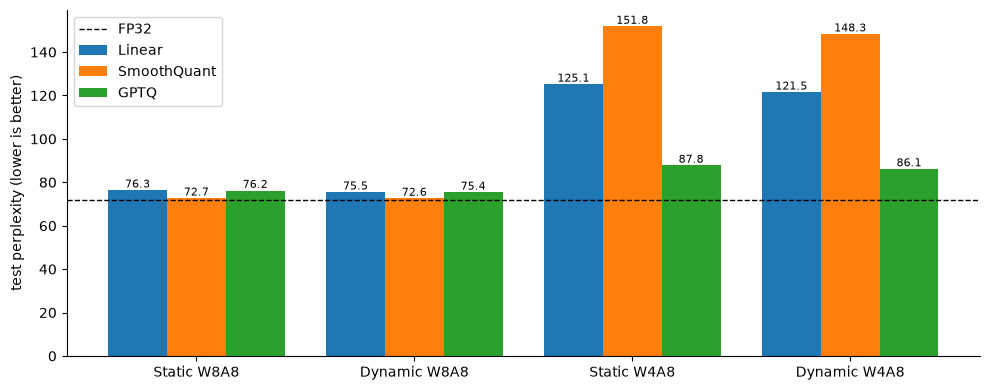


=== Quantization overheads ===


,when,cost
Static calibration,"offline, once",128 calibration blocks to record min/max (and ...
Dynamic range estimation,every forward pass,min/max reduction over each of 48 projection i...
SmoothQuant scaling,every forward pass,divide 24 c_proj inputs by s; c_attn / c_fc sc...
GPTQ reconstruction,"offline, once",≈90 s per bit-width + Hessian memory
Fake quantization,every forward pass,quantize-dequantize of every projection input ...


In [79]:
print("=== FP32 + 12 quantized configurations (test split) ===")
display(final_df.round(3))

print("\n=== Best method per setting ===")
display(best_df.round(3))

plot_final(final_df, "figures/t24_ppl_comparison.png")

print("\n=== Quantization overheads ===")
display(pd.DataFrame({
    "when": ["offline, once", "every forward pass", "every forward pass", "offline, once", "every forward pass"],
    "cost": ["128 calibration blocks to record min/max (and per-channel max for SmoothQuant)",
             "min/max reduction over each of 48 projection inputs (dynamic only)",
             "divide 24 c_proj inputs by s; c_attn / c_fc scales folded into LayerNorm (free)",
             f"≈{gptq_weights(8)[2]['GPTQ time (s)']:.0f} s per bit-width + Hessian memory",
             "quantize-dequantize of every projection input (simulation only)"]},
    index=["Static calibration", "Dynamic range estimation", "SmoothQuant scaling",
           "GPTQ reconstruction", "Fake quantization"]))

# Task 3 — QAT on ResNet-18 / CIFAR-10
## 3.1 Model Setup
Checkpoint: `edadaltocg/resnet18_cifar10` (edadaltocg/detectors), timm ResNet-18 with 3×3 stem, no max-pool.
Preprocessing: normalize with CIFAR-10 mean/std from the model card. Split: 45k train / 5k val (seed 42), 10k test.

In [80]:
pip install  timm torchvision

Note: you may need to restart the kernel to use updated packages.


In [90]:


import gc, torch.nn as nn, torchvision, torchvision.transforms as T, timm
from torch.utils.data import DataLoader, Subset

CKPT_URL = "https://huggingface.co/edadaltocg/resnet18_cifar10/resolve/main/pytorch_model.bin"
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)      # from the model card
BATCH, N_VAL = 128, 5000

def load_resnet():
    """Fresh copy of the pretrained checkpoint. Every experiment starts from this."""
    m = timm.create_model("resnet18", num_classes=10, pretrained=False)
    m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)                   # CIFAR stem
    m.maxpool = nn.Identity()
    m.load_state_dict(torch.hub.load_state_dict_from_url(
        CKPT_URL, map_location="cpu", file_name="resnet18_cifar10.pth"))
    return m.to(DEVICE).eval()

def cifar_loaders(root="data"):
    """Fixed 45k/5k train/val split from the training set; 10k test kept for the end."""
    norm = [T.ToTensor(), T.Normalize(MEAN, STD)]
    aug = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()] + norm)
    ds = lambda train, tf: torchvision.datasets.CIFAR10(root, train=train, download=True, transform=tf)
    idx = torch.randperm(50_000, generator=torch.Generator().manual_seed(SEED)).tolist()
    tr, va = idx[N_VAL:], idx[:N_VAL]
    dl = lambda d, shuffle=False: DataLoader(d, BATCH, shuffle=shuffle, num_workers=0,
                                             generator=torch.Generator().manual_seed(SEED))
    return {"train": dl(Subset(ds(True, aug), tr), shuffle=True),          # augmented, for training
            "train_eval": dl(Subset(ds(True, T.Compose(norm)), tr)),     # no augmentation
            "val": dl(Subset(ds(True, T.Compose(norm)), va)),
            "test": dl(ds(False, T.Compose(norm)))}

@torch.no_grad()
def evaluate_cls(model, loader):
    """Loss, Top-1, Top-5 and Macro-F1."""
    model.eval()
    loss, n, top1, top5, cm = 0.0, 0, 0, 0, torch.zeros(10, 10)
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        t5 = out.topk(5, 1).indices
        loss += F.cross_entropy(out, y, reduction="sum").item()
        top1 += (t5[:, 0] == y).sum().item()
        top5 += (t5 == y[:, None]).any(1).sum().item()
        cm += torch.bincount((y * 10 + t5[:, 0]).cpu(), minlength=100).view(10, 10)
        n += len(y)
    prec, rec = cm.diag() / cm.sum(0).clamp(min=1), cm.diag() / cm.sum(1).clamp(min=1)
    f1 = (2 * prec * rec / (prec + rec).clamp(min=1e-12)).mean().item()
    return {"loss": loss / n, "top1_%": 100 * top1 / n, "top5_%": 100 * top5 / n, "macro_f1": f1}

@torch.no_grad()
def profile_cnn(model, label, path="results/_tmp_cnn.pt"):
    """Task 1 methodology: batch 1, input 3×32×32, 10 warm-up + 30 timed passes."""
    gc.collect()
    if DEVICE == "mps": torch.mps.empty_cache()
    model.eval()
    x = torch.randn(PROFILE_BS, 3, 32, 32, device=DEVICE)
    torch.save(model.state_dict(), path); size = os.path.getsize(path) / 1e6; os.remove(path)

    counts = []                                              # MACs of every conv / linear layer
    def count(m, i, o):
        k = m.in_channels // m.groups * m.kernel_size[0] * m.kernel_size[1] if isinstance(m, nn.Conv2d) \
            else m.in_features
        counts.append(o.numel() * k)
    hooks = [m.register_forward_hook(count) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model(x)
    for h in hooks: h.remove()

    for _ in range(N_WARMUP): model(x)
    sync()
    proc, t = psutil.Process(), []
    proc.cpu_percent(None)
    for _ in range(N_MEASURE):
        t0 = time.perf_counter(); model(x); sync(); t.append((time.perf_counter() - t0) * 1000)
    cpu, t = proc.cpu_percent(None), np.array(t)

    model_bytes = sum(t.numel() * t.element_size() for t in list(model.parameters()) + list(model.buffers()))
    other = gpu_mem() - model_bytes
    peak = [gpu_mem()]
    hooks = [m.register_forward_hook(lambda *_: peak.append(gpu_mem())) for m in model.modules()]
    model(x); sync()
    for h in hooks: h.remove()
    macs = sum(counts)
    return {"config": label, "params_M": sum(p.numel() for p in model.parameters()) / 1e6,
            "serialized_MB": size, "GMACs": macs / 1e9, "GFLOPs": 2 * macs / 1e9,
            "latency_mean_ms": t.mean(), "latency_std_ms": t.std(ddof=1), "img_per_s": 1000 * PROFILE_BS / t.mean(),
            "peak_gpu_alloc_MB": (max(peak)-other) / 1e6, "process_rss_MB": proc.memory_info().rss / 1e6,
            "cpu_util_%_one_core": cpu, "gpu_util_%": "unavailable", "energy_mJ": "unavailable"}

### calling main function 

In [91]:
set_seed()
loaders = cifar_loaders()                    # downloads CIFAR-10 (~170 MB) the first time
fp32_cnn = load_resnet()                     # downloads the checkpoint the first time

CNN_RESULTS = {"FP32": {s: evaluate_cls(fp32_cnn, loaders[k])
                        for s, k in [("train", "train_eval"), ("val", "val"), ("test", "test")]}}
CNN_PROFILES = {"FP32": profile_cnn(fp32_cnn, "FP32")}

### results

In [92]:
print("Checkpoint: edadaltocg/resnet18_cifar10 (edadaltocg/detectors) | input 3×32×32")
print(f"Split: train {len(loaders['train'].dataset)} | val {len(loaders['val'].dataset)} | "
      f"test {len(loaders['test'].dataset)} | seed {SEED} | batch {BATCH}")

print("\n=== FP32 baseline accuracy ===")
display(pd.DataFrame(CNN_RESULTS["FP32"]).T.round(4))

print("\n=== FP32 baseline profile (batch 1) ===")
display(pd.Series(CNN_PROFILES["FP32"]).to_frame("value"))

Checkpoint: edadaltocg/resnet18_cifar10 (edadaltocg/detectors) | input 3×32×32
Split: train 45000 | val 5000 | test 10000 | seed 42 | batch 128

=== FP32 baseline accuracy ===


,loss,top1_%,top5_%,macro_f1
train,0.0008,99.9978,100.00,1.0000
val,0.0007,100.0000,100.00,1.0000
test,0.2042,94.9800,99.86,0.9498



=== FP32 baseline profile (batch 1) ===


,value
config,FP32
params_M,11.173962
serialized_MB,44.774475
GMACs,0.555423
GFLOPs,1.110845
latency_mean_ms,2.900376
latency_std_ms,0.23192
img_per_s,344.782836
peak_gpu_alloc_MB,45.782984
process_rss_MB,760.774656


## 3.2 QAT Implementation


In [93]:
# ---------- 3.2 QAT ----------
QAT_CFG = dict(epochs=5, lr=1e-3, momentum=0.9, weight_decay=5e-4,
               init_batches=20, ema=0.9, freeze_epoch=2)

class FakeQuantSTE(torch.autograd.Function):
    """Forward: quantize -> dequantize.  Backward (STE): gradient passes unchanged where the
    value is inside the clip range [qmin, qmax], and is 0 where it was clipped."""
    @staticmethod
    def forward(ctx, x, S, Z, qmin, qmax):
        v = x / S + Z
        ctx.save_for_backward((v >= qmin) & (v <= qmax))
        return (torch.clamp(torch.round(v), qmin, qmax) - Z) * S
    @staticmethod
    def backward(ctx, g):
        (inside,) = ctx.saved_tensors
        return g * inside, None, None, None, None

class QATMixin:
    """Adds fake-quant weights (symmetric per-output-channel) and fake-quant inputs
    (asymmetric per-tensor uint8, min/max observer) to a Conv2d / Linear. Bias stays FP32."""
    def setup_qat(self, bits, ema):
        self.bits, self.ema, self.obs = bits, ema, "init"
        dev = self.weight.device
        self.register_buffer("x_min", torch.tensor(float("inf"), device=dev))
        self.register_buffer("x_max", torch.tensor(float("-inf"), device=dev))

    def fq_weight(self):
        Qb = 2 ** (self.bits - 1) - 1
        S = self.weight.detach().abs().amax(dim=tuple(range(1, self.weight.dim())), keepdim=True) / Qb
        S = torch.where(S > 0, S, torch.ones_like(S))
        return FakeQuantSTE.apply(self.weight, S, 0.0, -Qb, Qb)      # master weight stays FP32

    def fq_input(self, x):
        with torch.no_grad():
            if self.obs == "init":                                 # running min/max over init batches
                self.x_min.copy_(torch.minimum(self.x_min, x.min()))
                self.x_max.copy_(torch.maximum(self.x_max, x.max()))
            elif self.obs == "ema" and self.training:              # moving average while training
                self.x_min.mul_(self.ema).add_((1 - self.ema) * x.min())
                self.x_max.mul_(self.ema).add_((1 - self.ema) * x.max())
        if self.obs == "init":
            return x
        return FakeQuantSTE.apply(x, *act_qparams(self.x_min, self.x_max), 0, 255)

class QATConv2d(QATMixin, nn.Conv2d):
    def forward(self, x): return self._conv_forward(self.fq_input(x), self.fq_weight(), self.bias)

class QATLinear(QATMixin, nn.Linear):
    def forward(self, x): return F.linear(self.fq_input(x), self.fq_weight(), self.bias)

def to_qat(model, bits):
    """Turn every Conv2d / Linear into its QAT version in place (weights are kept)."""
    for m in model.modules():
        if type(m) in (nn.Conv2d, nn.Linear):
            m.__class__ = QATConv2d if isinstance(m, nn.Conv2d) else QATLinear
            m.setup_qat(bits, QAT_CFG["ema"])
    return model

def set_observers(model, mode):
    for m in model.modules():
        if isinstance(m, QATMixin): m.obs = mode

def train_qat(bits, cfg=QAT_CFG):
    """Fresh checkpoint -> QAT -> init observers -> fine-tune -> best epoch by validation."""
    set_seed()
    model = to_qat(load_resnet(), bits)
    with torch.no_grad():                                    # 1) initialise observers on training data
        model.eval()
        for i, (x, _) in enumerate(loaders["train"]):
            if i == cfg["init_batches"]: break
            model(x.to(DEVICE))
    set_observers(model, "ema")

    opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=cfg["momentum"],
                          weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, cfg["epochs"])
    hist, best, t0 = [], None, time.perf_counter()
    for ep in range(1, cfg["epochs"] + 1):
        if ep > cfg["freeze_epoch"]: set_observers(model, "frozen")      # 2) freeze observers
        model.train()
        tl, tc, n = 0.0, 0, 0
        for x, y in loaders["train"]:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x); loss = F.cross_entropy(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        sched.step()
        v = evaluate_cls(model, loaders["val"])
        hist.append({"epoch": ep, "train_loss": tl / n, "train_acc": 100 * tc / n, "val_loss": v["loss"],
                     "val_acc": v["top1_%"], "observers": "EMA" if ep <= cfg["freeze_epoch"] else "frozen"})
        print(f"W{bits}A8 epoch {ep}: train loss {tl/n:.4f} acc {100*tc/n:.2f}% | "
              f"val loss {v['loss']:.4f} acc {v['top1_%']:.2f}% | {(time.perf_counter()-t0)/60:.1f} min")
        key = (v["top1_%"], -v["loss"])                      # 3) select by validation only
        if best is None or key > best[0]:
            best = (key, ep, {k: t.detach().clone() for k, t in model.state_dict().items()})
    model.load_state_dict(best[2])
    set_observers(model, "frozen"); model.eval()             # 4) frozen for final evaluation
    return model, pd.DataFrame(hist).set_index("epoch"), \
           {"best_epoch": best[1], "train_time_min": (time.perf_counter() - t0) / 60}

### calling functions 

In [94]:
QAT = {}
for bits in (8, 4):
    model, hist, info = train_qat(bits)
    QAT[f"W{bits}A8"] = {"model": model, "hist": hist, "info": info}

W8A8 epoch 1: train loss 0.0026 acc 99.97% | val loss 0.0008 acc 100.00% | 1.3 min
W8A8 epoch 2: train loss 0.0024 acc 99.98% | val loss 0.0007 acc 100.00% | 2.5 min
W8A8 epoch 3: train loss 0.0024 acc 99.98% | val loss 0.0008 acc 100.00% | 3.8 min
W8A8 epoch 4: train loss 0.0027 acc 99.96% | val loss 0.0008 acc 100.00% | 5.0 min
W8A8 epoch 5: train loss 0.0022 acc 99.99% | val loss 0.0008 acc 100.00% | 6.4 min
W4A8 epoch 1: train loss 0.0038 acc 99.94% | val loss 0.0008 acc 100.00% | 1.3 min
W4A8 epoch 2: train loss 0.0035 acc 99.95% | val loss 0.0010 acc 99.98% | 2.6 min
W4A8 epoch 3: train loss 0.0026 acc 99.99% | val loss 0.0008 acc 100.00% | 3.8 min
W4A8 epoch 4: train loss 0.0028 acc 99.96% | val loss 0.0008 acc 100.00% | 5.1 min
W4A8 epoch 5: train loss 0.0028 acc 99.96% | val loss 0.0008 acc 100.00% | 6.3 min


## results

In [95]:
print("=== QAT settings (same for W8A8 and W4A8) ===")
display(pd.Series({
    "checkpoint": "edadaltocg/resnet18_cifar10 (fresh copy per run)",
    "quantized layers": "all Conv2d + Linear (weights and inputs); biases FP32",
    "weights": "symmetric, per-output-channel, scale = max|W| / (2^(b-1)-1), recomputed every step",
    "activations": "asymmetric uint8, per-tensor, min/max observer",
    "observers": f"init on {QAT_CFG['init_batches']} training batches (running min/max), "
                 f"EMA (m={QAT_CFG['ema']}) epochs 1–{QAT_CFG['freeze_epoch']}, frozen after",
    "STE": "gradient = 1 inside clip range, 0 outside",
    "BatchNorm": "kept separate in FP32, not folded; running stats update during training",
    "optimizer": f"SGD momentum {QAT_CFG['momentum']}, weight decay {QAT_CFG['weight_decay']}",
    "learning rate": f"{QAT_CFG['lr']} with cosine decay",
    "epochs / batch size": f"{QAT_CFG['epochs']} / {BATCH}",
    "augmentation": "RandomCrop(32, pad 4) + RandomHorizontalFlip (train only)",
    "checkpoint selection": "best validation Top-1, ties broken by lowest validation loss",
    "seed": SEED, "execution": "SIMULATED (fake quantization, FP32 kernels on MPS)",
}).to_frame("value"))

for k, v in QAT.items():
    print(f"\n=== {k}: best epoch {v['info']['best_epoch']} | "
          f"training time {v['info']['train_time_min']:.1f} min ===")
    display(v["hist"].round(4))

=== QAT settings (same for W8A8 and W4A8) ===


,value
checkpoint,edadaltocg/resnet18_cifar10 (fresh copy per run)
quantized layers,all Conv2d + Linear (weights and inputs); bias...
weights,"symmetric, per-output-channel, scale = max|W| ..."
activations,"asymmetric uint8, per-tensor, min/max observer"
observers,"init on 20 training batches (running min/max),..."
STE,"gradient = 1 inside clip range, 0 outside"
BatchNorm,"kept separate in FP32, not folded; running sta..."
optimizer,"SGD momentum 0.9, weight decay 0.0005"
learning rate,0.001 with cosine decay
epochs / batch size,5 / 128



=== W8A8: best epoch 2 | training time 6.4 min ===


,train_loss,train_acc,val_loss,val_acc,observers
epoch,,,,,
1,0.0026,99.9689,0.0008,100.0,EMA
2,0.0024,99.9800,0.0007,100.0,EMA
3,0.0024,99.9778,0.0008,100.0,frozen
4,0.0027,99.9622,0.0008,100.0,frozen
5,0.0022,99.9889,0.0008,100.0,frozen



=== W4A8: best epoch 5 | training time 6.3 min ===


,train_loss,train_acc,val_loss,val_acc,observers
epoch,,,,,
1,0.0038,99.9400,0.0008,100.00,EMA
2,0.0035,99.9533,0.0010,99.98,EMA
3,0.0026,99.9867,0.0008,100.00,frozen
4,0.0028,99.9600,0.0008,100.00,frozen
5,0.0028,99.9644,0.0008,100.00,frozen


## 3.3 Results and Profiling

In [96]:
# ---------- 3.3 Results ----------
@torch.no_grad()
def export_int(model):
    """Integer checkpoint: int8 weights (4-bit values stored unpacked in int8) + FP32 scales,
    activation scale + uint8 zero-point, FP32 biases, FP32 BatchNorm."""
    sd, qat = {}, {n: m for n, m in model.named_modules() if isinstance(m, QATMixin)}
    for n, m in qat.items():
        Qb = 2 ** (m.bits - 1) - 1
        S = m.weight.abs().amax(dim=tuple(range(1, m.weight.dim())), keepdim=True) / Qb
        S = torch.where(S > 0, S, torch.ones_like(S))
        aS, aZ = act_qparams(m.x_min, m.x_max)
        sd[f"{n}.w_int"] = torch.clamp(torch.round(m.weight / S), -Qb, Qb).to(torch.int8).cpu()
        sd[f"{n}.w_scale"], sd[f"{n}.a_scale"], sd[f"{n}.a_zp"] = S.flatten().cpu(), aS.cpu(), aZ.to(torch.uint8).cpu()
        if m.bias is not None: sd[f"{n}.bias"] = m.bias.cpu()
    for k, v in model.state_dict().items():                          # BatchNorm etc. stay FP32
        if k.rsplit(".", 1)[0] not in qat: sd[k] = v.cpu()
    return sd

def storage_sizes(model, bits, path="results/_tmp_int.pt"):
    """Actual size of the integer export, and theoretical size with weights packed at `bits`."""
    sd = export_int(model)
    torch.save(sd, path); actual = os.path.getsize(path) / 1e6; os.remove(path)
    packed = sum(v.numel() * (bits / 8 if k.endswith("w_int") else v.element_size()) for k, v in sd.items()) / 1e6
    return actual, packed

@torch.no_grad()
def qat_layer_errors(model, n_batches=4):
    """E_W vs master weights and vs original pretrained weights; E_X on fixed validation batches."""
    err = lambda a, b: ((a - b).pow(2).sum() / (a.pow(2).sum() + EPS)).item()
    layers = {n: m for n, m in model.named_modules() if isinstance(m, QATMixin)}
    orig, acc = load_resnet().state_dict(), {n: [0.0, 0.0] for n in layers}
    def hook(m, inp, n):
        x = inp[0]; d = x - m.fq_input(x)
        acc[n][0] += d.pow(2).sum().item(); acc[n][1] += x.pow(2).sum().item()
    hs = [m.register_forward_pre_hook(lambda m, i, n=n: hook(m, i, n)) for n, m in layers.items()]
    model.eval()
    for i, (x, _) in enumerate(loaders["val"]):
        if i == n_batches: break
        model(x.to(DEVICE))
    for h in hs: h.remove()
    return pd.DataFrame([{"layer": n, "E_W (vs master)": err(m.weight, m.fq_weight()),
                          "E_W (vs pretrained)": err(orig[f"{n}.weight"], m.fq_weight()),
                          "E_X": acc[n][0] / (acc[n][1] + EPS)} for n, m in layers.items()]).set_index("layer")

def plot_curves(path):
    """Training/validation loss and accuracy per epoch for both QAT runs."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for k, v in QAT.items():
        h = v["hist"]
        axes[0].plot(h.index, h.train_loss, "o-", label=f"{k} train"); axes[0].plot(h.index, h.val_loss, "s--", label=f"{k} val")
        axes[1].plot(h.index, h.train_acc, "o-", label=f"{k} train"); axes[1].plot(h.index, h.val_acc, "s--", label=f"{k} val")
    for ax, t in zip(axes, ["loss", "Top-1 accuracy (%)"]):
        ax.set_xlabel("epoch"); ax.set_title(t); ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
    axes[0].axvline(QAT_CFG["freeze_epoch"] + 0.5, color="grey", ls=":", lw=1)       # observers frozen
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()

def plot_qat_errors(errs, path):
    """Per-layer E_W and E_X for W8A8 vs W4A8."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for k, e in errs.items():
        axes[0].plot(range(len(e)), e["E_W (vs master)"], "o-", label=k)
        axes[1].plot(range(len(e)), e["E_X"], "o-", label=k)
    for ax, t in zip(axes, ["weight error $E_W$", "activation error $E_X$"]):
        ax.set_yscale("log"); ax.set_title(t); ax.legend()
        ax.set_xticks(range(len(e)), e.index, rotation=90, fontsize=7); ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()

## calling main functions

In [97]:
for v in ["model", "m", "sm"]: globals().pop(v, None)      # free leftover GPT-2 models (memory)
gc.collect(); torch.mps.empty_cache()

rows, QAT_ERRS = {}, {}
for k, model in [("FP32", fp32_cnn)] + [(k, v["model"]) for k, v in QAT.items()]:
    tr, te = evaluate_cls(model, loaders["train_eval"]), evaluate_cls(model, loaders["test"])
    prof = profile_cnn(model, k)
    row = {"train Top-1 %": tr["top1_%"], "test Top-1 %": te["top1_%"], "test Top-5 %": te["top5_%"],
           "test Macro-F1": te["macro_f1"], **prof}
    if k == "FP32":
        row.update({"int export MB": prof["serialized_MB"], "packed MB (theory)": prof["serialized_MB"],
                    "execution": "FP32 kernels"})
    else:
        bits = int(k[1])
        row["int export MB"], row["packed MB (theory)"] = storage_sizes(model, bits)
        row["execution"] = "SIMULATED: fake quant + FP32 kernels"
        QAT_ERRS[k] = qat_layer_errors(model)
    rows[k] = row
final_cnn = pd.DataFrame(rows).T.rename(columns={"serialized_MB": "QAT checkpoint MB (FP32 master)"})
final_cnn.to_csv("results/task3_final_table.csv")

### results

=== FP32 vs QAT W8A8 vs QAT W4A8 (test set, batch-1 profiling, input 3×32×32) ===


,train Top-1 %,test Top-1 %,test Top-5 %,test Macro-F1,config,params_M,QAT checkpoint MB (FP32 master),GMACs,GFLOPs,latency_mean_ms,latency_std_ms,img_per_s,peak_gpu_alloc_MB,process_rss_MB,cpu_util_%_one_core,gpu_util_%,energy_mJ,int export MB,packed MB (theory),execution
FP32,99.997778,94.98,99.86,0.949797,FP32,11.173962,44.774475,0.555423,1.110845,3.808201,2.742466,262.59116,45.782984,795.574272,76.9,unavailable,unavailable,44.774475,44.774475,FP32 kernels
W8A8,100.0,94.78,99.87,0.947796,W8A8,11.173962,44.786209,0.555423,1.110845,14.798186,0.409891,67.57585,45.783152,772.99712,50.4,unavailable,unavailable,11.315148,11.260697,SIMULATED: fake quant + FP32 kernels
W4A8,99.995556,94.86,99.87,0.948555,W4A8,11.173962,44.786209,0.555423,1.110845,14.955267,0.556343,66.866076,45.783152,830.029824,51.5,unavailable,unavailable,11.315148,5.678521,SIMULATED: fake quant + FP32 kernels


W8A8: best epoch 2 | training time 6.4 min
W4A8: best epoch 5 | training time 6.3 min


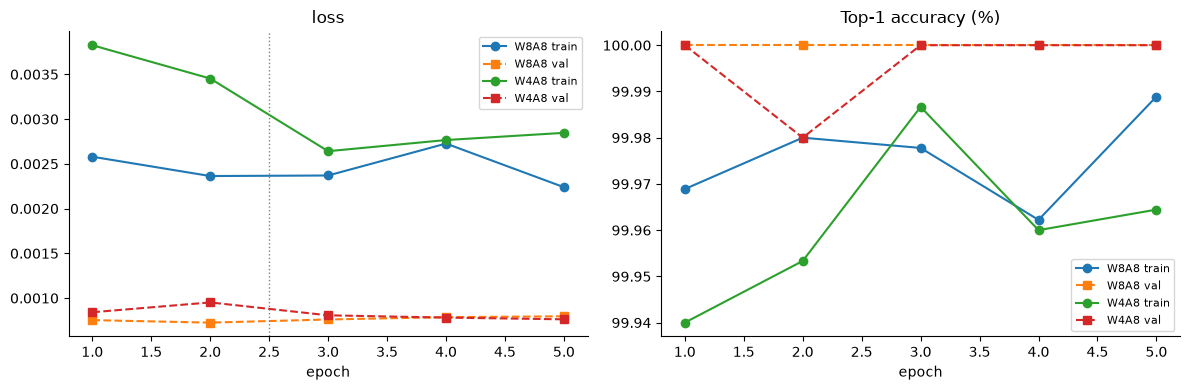


=== Layer-wise normalized reconstruction error (frozen quantizers, 4 fixed validation batches) ===


W8A8                                \
                      E_W (vs master) E_W (vs pretrained)       E_X   
layer                                                                 
conv1                        3.21e-05            5.24e-05  2.30e-05   
layer1.0.conv1               1.88e-04            2.11e-04  1.83e-04   
layer1.0.conv2               1.42e-04            1.67e-04  2.04e-04   
layer1.1.conv1               1.73e-04            1.99e-04  3.26e-04   
layer1.1.conv2               9.99e-05            1.26e-04  1.47e-04   
layer2.0.conv1               7.94e-05            1.09e-04  1.73e-04   
layer2.0.conv2               8.94e-05            1.20e-04  1.22e-04   
layer2.0.downsample.0        6.06e-05            8.63e-05  1.73e-04   
layer2.1.conv1               1.11e-04            1.44e-04  1.86e-04   
layer2.1.conv2               9.78e-05            1.33e-04  1.90e-04   
layer3.0.conv1               1.02e-04            1.35e-04  3.90e-04   
layer3.0.conv2               1.09e-04            1.47e-04  1.53e-04   
layer3.0.downsample.0        5.84e-05            8.57e-05  3.90e-04   
layer3.1.conv1               1.21e-04            1.63e-04  2.68e-04   
layer3.1.conv2               1.18e-04            1.54e-04  3.08e-04   
layer4.0.conv1               1.27e-04            1.53e-04  5.87e-04   
layer4.0.conv2               1.55e-04            1.77e-04  4.83e-04   
layer4.0.downsample.0        7.39e-05            9.21e-05  5.87e-04   
layer4.1.conv1               2.21e-04            2.59e-04  1.87e-04   
layer4.1.conv2               1.77e-04            1.99e-04  8.51e-05   
fc                           1.09e-04            1.11e-04  9.34e-05   

                                 W4A8                                
                      E_W (vs master) E_W (vs pretrained)       E_X  
layer                                                                
conv1                        1.01e-02            9.65e-03  2.30e-05  
layer1.0.conv1               5.21e-02            5.15e-02  1.58e-04  
layer1.0.conv2               4.59e-02            4.55e-02  2.06e-04  
layer1.1.conv1               5.27e-02            5.21e-02  3.49e-04  
layer1.1.conv2               3.29e-02            3.25e-02  1.61e-04  
layer2.0.conv1               2.60e-02            2.58e-02  1.70e-04  
layer2.0.conv2               2.95e-02            2.93e-02  1.18e-04  
layer2.0.downsample.0        2.00e-02            1.97e-02  1.70e-04  
layer2.1.conv1               3.65e-02            3.62e-02  1.66e-04  
layer2.1.conv2               3.21e-02            3.19e-02  1.78e-04  
layer3.0.conv1               3.37e-02            3.34e-02  3.86e-04  
layer3.0.conv2               3.60e-02            3.56e-02  1.33e-04  
layer3.0.downsample.0        1.93e-02            1.92e-02  3.86e-04  
layer3.1.conv1               3.98e-02            3.94e-02  2.85e-04  
layer3.1.conv2               3.89e-02            3.86e-02  2.66e-04  
layer4.0.conv1               4.17e-02            4.13e-02  4.95e-04  
layer4.0.conv2               5.09e-02            5.04e-02  4.79e-04  
layer4.0.downsample.0        2.41e-02            2.39e-02  4.95e-04  
layer4.1.conv1               7.10e-02            7.04e-02  1.90e-04  
layer4.1.conv2               5.82e-02            5.78e-02  8.58e-05  
fc                           3.93e-02            3.91e-02  9.99e-05

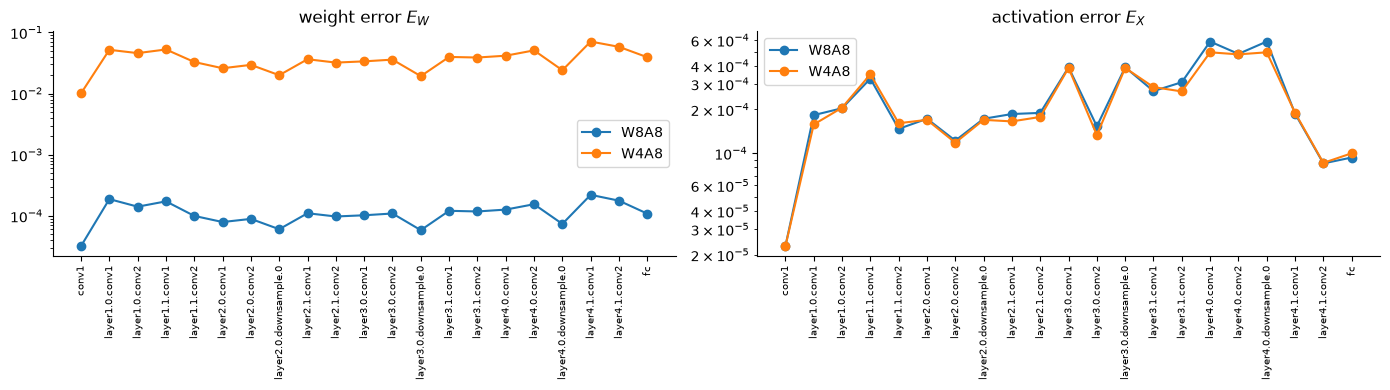

In [98]:
pd.set_option("display.max_columns", None)
print("=== FP32 vs QAT W8A8 vs QAT W4A8 (test set, batch-1 profiling, input 3×32×32) ===")
display(final_cnn)

for k, v in QAT.items():
    print(f"{k}: best epoch {v['info']['best_epoch']} | training time {v['info']['train_time_min']:.1f} min")

plot_curves("figures/t33_training_curves.png")

print("\n=== Layer-wise normalized reconstruction error (frozen quantizers, 4 fixed validation batches) ===")
display(pd.concat(QAT_ERRS, axis=1).map(lambda v: f"{v:.2e}"))
plot_qat_errors(QAT_ERRS, "figures/t33_layer_errors.png")

## 3.4 Analysis

**Accuracy.** Both QAT models stay within 0.2% of FP32.

| Model | Test Top-1 | Top-5 | Macro-F1 |
|---|---|---|---|
| FP32 | 94.98% | 99.86% | 0.9498 |
| W8A8 QAT | 94.78% | 99.87% | 0.9478 |
| W4A8 QAT | 94.86% | 99.87% | 0.9486 |

The W8A8 vs W4A8 difference (8 of 10,000 images) is noise; both are equivalent to FP32.

**Convergence.** W8A8 needs almost no adaptation (training loss ≈ 0.0023 throughout).
W4A8 starts 46% higher (0.0038 vs 0.0026) and converges to the W8A8 level by epoch 3, right
after the observers freeze. Validation accuracy saturates at ≈100% because the public
checkpoint was trained on the full CIFAR-10 training set, so only the test set is truly held out.

**Quantization error.** W4 weight error is ≈300× larger than W8 (≈4×10⁻² vs 1×10⁻⁴), yet
accuracy is the same: QAT adapts the weights and BatchNorm to the rounding. Activation error
is the same for both (≈10⁻⁴), since both use the same A8 quantizer.

**Storage.** Integer export: 44.77 → 11.32 MB (−75%) for both. 4-bit weights are stored
unpacked in int8; packed W4 would be 5.68 MB (−87%), theory only.

**Latency, memory, energy.** Inference is simulated (fake quantization + FP32 kernels on MPS),
so QAT models are ≈4× slower (14.8–15.0 ms vs 3.8 ms) due to the extra quantize-dequantize work.
MACs (0.555 G) and FLOPs (1.111 G) are unchanged. Peak allocated GPU memory is the same for all
three models (≈45.8 MB), because simulated QAT still runs FP32 tensors. Energy is unavailable on
macOS without admin access; real INT8 kernels would lower arithmetic and memory energy, but this
is not measured.

**Training cost.** QAT needs fine-tuning (5 epochs per model): 6.4 min for W8A8 and
6.3 min for W4A8 on MPS. PTQ needs none.

**Conclusion.** QAT keeps both W8A8 and W4A8 at FP32-level accuracy while cutting real
storage by 75%. Unlike 4-bit PTQ on GPT-2, training with quantization in the loop lets the
model recover from the much larger 4-bit weight error.